# Centromeric heterochromatin of *Capra hircus*
A case study with public data

This notebook goes from the raw genome downloads to the statistics, in three sections. It runs locally and saves every table it produces in `data/`.

| Section | What it does | Main output |
|---|---|---|
| 1 · Data and assemblies | Downloads the T2T-goat2.0 genomes (NCBI) and PacBio reads of other breeds (ENA), and standardises names | `chromosomes.csv`, `manifest.csv` |
| 2 · Satellites and centromeres | Orients each chromosome, finds the satellite units with SRF, annotates them and delimits each centromere | `centromeres_master.csv` |
| 3 · Statistics and figures | H1 (scaling), H2 (composition), H3 (homologs) and variation between breeds | results and figures |

Data. The T2T-goat2.0 genome of a male Inner Mongolia Cashmere goat, `IMCG_204112` (Wu et al. 2024, *Nat Commun* 15:10041). Three assemblies are used: the collapsed one (`GCA_041735815.1`) and its two haplotypes, P (`GCA_041053135.1`) and M (`GCA_040970035.1`). The PacBio reads of other breeds come from BioProject `PRJNA1062519`.

Decisions made up front:
- CENP-A ChIP-seq was tried and dropped (see `docs/NOTE_chipseq_removed.Rmd`). Centromeres are delimited by satellite density, so the definition is operational.
- The comparison between breeds is secondary and exploratory (section 3.4).
- Section 3 only reads the tables in `data/`, so it can be run on its own.

Things to keep in mind when reading the results:
- All the sequence comes from one animal. P and M are its two haplotypes, not two individuals.
- A centromere here is a satellite-rich block, not the CENP-A domain. It can be longer than the 0.6–8.51 Mb reported by Wu et al.
- SatIII is a 22-bp motif that aligns poorly, so it is probably underestimated.
- The X has its satellite block about 7.2 Mb from the end because its short arm holds the pseudoautosomal region. Section 2.7 checks that this is not an error. It is still an influential point in H1 and H2.
- Three centromeres of haplotype M have very little satellite, which looks like missing sequence in the assembly. They are flagged `low_satellite` and the analyses are repeated without them.

To run it, open it from the repository root (or from `notebooks/`) with the packages in `requirements.txt`. minimap2 and samtools come from Homebrew. KMC, SRF and k8 are installed in `tools/` by cell 1.2.

# Section 1 · Data and assemblies

## 1.1 · Configuration

In [1]:
import os, sys, re, gzip, hashlib, subprocess, shutil, json, io, time, shlex, platform
import urllib.request
from pathlib import Path
import numpy as np, pandas as pd, requests

def urlopen_retry(url, tries=6):           # intermittent DNS/network failures: retry with increasing wait
    for k in range(tries):
        try: return urllib.request.urlopen(url, timeout=60)
        except Exception as e:
            if k == tries-1: raise
            time.sleep(10*(k+1))
Q = lambda p: shlex.quote(str(p))          # paths with spaces (e.g. 'Capra hircus') in shell commands

# ---------- parameters ----------
DOWNLOAD_READS  = True      # PacBio reads (subsampled); False to skip them
PACBIO_BASES_GB = 0.5       # Gb of bases to keep per run (~0.17x per breed; ENA delivers ~0.5 MB/s)
WINDOW_MB       = 15        # proximal window per chromosome (centromeres span 0.6–10 Mb)
MAX_GAP         = 500_000   # bp; maximum separation between satellite blocks of the same centromere
MIN_SAT_FRAC    = 0.30      # a block with less satellite than this fraction is flagged low_satellite
KINDS_SAT       = ['SatI','SatII','SatIII']
SEED            = 20241013
THREADS         = os.cpu_count() or 2

# ---------- paths (all relative to the project folder) ----------
BASE  = Path.cwd()
if BASE.name == 'notebooks': BASE = BASE.parent        # allow running from notebooks/
DATA  = BASE/'data'; TAB = DATA                         # tables, raw downloads and reads
RAW, READS, FIG = DATA/'raw_ncbi', DATA/'reads', DATA/'figures'
ROOT  = BASE/'work'; CLEAN = ROOT/'clean'               # renamed FASTA and windows (regenerated in minutes)
TOOLS = BASE/'tools'
for d in (RAW, READS, FIG, CLEAN, TOOLS): d.mkdir(parents=True, exist_ok=True)

# ---------- sources ----------
ASSEMBLIES = {   # label -> (GenBank accession, NCBI name)
    'T2T': ('GCA_041735815.1', 'T2T-goat2.0'),    # collapsed (30 chromosomes + Y)
    'P'  : ('GCA_041053135.1', 'T2T-goat2.0P'),   # paternal haplotype (autosomes + Y)
    'M'  : ('GCA_040970035.1', 'T2T-goat2.0M'),   # maternal haplotype (autosomes + X)
}
ENA_PROJECT = 'PRJNA1062519'   # NCBI/ENA; CNCB mirror: PRJCA022847
print('Project:', BASE); print('Tables :', TAB)

Project: <repo>
Tables : <repo>/data


## 1.2 · Tools

In [2]:
# minimap2 and samtools: Homebrew (brew install minimap2 samtools). KMC, SRF and k8 are installed in ./tools (macOS arm64).
for t in ('minimap2', 'samtools'):
    assert shutil.which(t), f'missing {t}: brew install {t}'
KMC, KMC_DUMP = TOOLS/'bin'/'kmc', TOOLS/'bin'/'kmc_dump'
SRF, SRFUTILS, K8 = TOOLS/'srf'/'srf', TOOLS/'srf'/'srfutils.js', TOOLS/'k8'
if not all(p.exists() for p in (KMC, KMC_DUMP, SRF, SRFUTILS, K8)):
    assert platform.system() == 'Darwin' and platform.machine() == 'arm64', 'automatic installation only for macOS arm64'
    script = f'''
set -e; cd {Q(TOOLS)}
curl -sL -o kmc.tgz https://github.com/refresh-bio/KMC/releases/download/v3.2.4/KMC3.2.4.mac.arm64.tar.gz && tar xzf kmc.tgz
mkdir -p srf && curl -sL https://github.com/lh3/srf/archive/refs/heads/master.tar.gz | tar xz -C srf --strip-components=1 && make -C srf > /dev/null
curl -sL -o k8.tbz https://github.com/attractivechaos/k8/releases/download/v1.2/k8-1.2.tar.bz2 && tar xjf k8.tbz && cp k8-1.2/k8-arm64-Darwin k8 && chmod +x k8
rm -rf kmc.tgz k8.tbz k8-1.2
'''
    subprocess.run(['bash', '-c', script], check=True)
for p in (KMC, KMC_DUMP, SRF, SRFUTILS, K8): assert p.exists(), p
print('Tools OK:', {t: shutil.which(t) for t in ('minimap2', 'samtools')}, '+ KMC, SRF, k8 in', TOOLS)

Tools OK: {'minimap2': '/opt/homebrew/bin/minimap2', 'samtools': '/opt/homebrew/bin/samtools'} + KMC, SRF, k8 in <repo>/tools


## 1.3 · Assembly download (NCBI) with MD5 check
About 0.86 GB per assembly. If the file is already there and its MD5 matches, it is not downloaded again.

In [3]:
def ncbi_dir(acc, name):
    n = acc.split('_')[1].split('.')[0]
    return f'https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/{n[:3]}/{n[3:6]}/{n[6:9]}/{acc}_{name}/'

def md5_file(p, chunk=1<<24):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        while b := f.read(chunk): h.update(b)
    return h.hexdigest()

def fetch(url, dest):
    subprocess.run(['curl', '-sS', '-L', '--retry', '5', '-C', '-', '-o', str(dest), url], check=True)

manifest = []   # (type, id, file, bytes, md5, source)
for hap, (acc, name) in ASSEMBLIES.items():
    base = ncbi_dir(acc, name); stem = f'{acc}_{name}'
    md5s = {l.split()[1].lstrip('./'): l.split()[0] for l in urlopen_retry(base + 'md5checksums.txt').read().decode().splitlines() if l.strip()}
    fa_gz = RAW/(stem + '_genomic.fna.gz')
    if not (fa_gz.exists() and md5_file(fa_gz) == md5s[stem + '_genomic.fna.gz']):   # already downloaded and intact: not repeated
        fetch(base + stem + '_genomic.fna.gz', fa_gz)
    fetch(base + stem + '_assembly_report.txt', RAW/(stem + '_assembly_report.txt'))
    got = md5_file(fa_gz)
    assert got == md5s[stem + '_genomic.fna.gz'], f'MD5 mismatch in {hap}'
    manifest.append(('assembly', hap, stem + '_genomic.fna.gz', (RAW/(stem+'_genomic.fna.gz')).stat().st_size, got, base))
    print(hap, name, 'OK  MD5', got)

T2T T2T-goat2.0 OK  MD5 87c5212a7acb095d1d9358c67e3c952e


P T2T-goat2.0P OK  MD5 9e4880b5d6ecd19ac677b400f17eaec6


M T2T-goat2.0M OK  MD5 b5c25a68070fff3eec4f5258a2534546


## 1.4 · Chromosome table and renaming
Names come from the NCBI sequence report and are standardised to `CHI1…CHI29`, `CHIX` and `CHIY`. In 2.0M the X appears as `30` (144.69 Mb, the same length as the X of T2T-goat2.0), so it is renamed by length. Each haplotype has 30 chromosomes: 29 autosomes plus one sex chromosome (the Y in P, the X in M). Their gaps are detected in section 2.

In [4]:
import pandas as pd
def sequence_report(acc):
    rows, token = [], None
    while True:
        u = f'https://api.ncbi.nlm.nih.gov/datasets/v2/genome/accession/{acc}/sequence_reports?page_size=1000' + (f'&page_token={token}' if token else '')
        d = json.load(urlopen_retry(u)); rows += d['reports']; token = d.get('next_page_token')
        if not token: return rows

chrom_rows = []
for hap, (acc, name) in ASSEMBLIES.items():
    for r in sequence_report(acc):
        chrom_rows.append(dict(hap=hap, assembly=name, accession=r['genbank_accession'], ncbi_name=r.get('chr_name'),
                               role=r.get('role'), length=r['length'], gc_percent=r.get('gc_percent')))
chroms = pd.DataFrame(chrom_rows)
chroms['placed'] = chroms.role.eq('assembled-molecule') & chroms.ncbi_name.notna()
# 2.0M names the X as '30': detected by its length, identical to the X of T2T-goat2.0
x_len = chroms[(chroms.hap=='T2T') & (chroms.ncbi_name=='X')].length.iloc[0]
fix = chroms.placed & chroms.ncbi_name.str.fullmatch(r'\d+').fillna(False) & (chroms.length==x_len)
chroms.loc[fix, 'ncbi_name'] = 'X'
chroms['chr'] = chroms.apply(lambda r: f'CHI{r.ncbi_name}' if r.placed else None, axis=1)
chroms['seqname'] = chroms.apply(lambda r: f'{r.hap}_{r.chr}' if r.placed else f'{r.hap}_unplaced_{r.accession}', axis=1)
chroms['kind'] = chroms.chr.map(lambda c: None if c is None else ('X' if c=='CHIX' else 'Y' if c=='CHIY' else 'autosome'))

print(chroms.groupby(['hap','placed']).agg(n=('length','size'), Mb=('length', lambda s: round(s.sum()/1e6,1))).unstack())
# expected checks according to the paper
for hap, g in chroms[chroms.placed].groupby('hap'):
    au = (g.kind=='autosome').sum()
    print(hap, 'autosomes:', au, '| X:', (g.kind=='X').sum(), '| Y:', (g.kind=='Y').sum())
    assert au == 29, 'expected 29 autosomes'
    assert (g.kind=='X').sum() == (hap in ('T2T','M')) and (g.kind=='Y').sum() == (hap in ('T2T','P')), 'unexpected X/Y'
chroms.to_csv(TAB/'chromosomes.csv', index=False)
chroms[chroms.placed].head(3)

          n      Mb
placed True    True
hap                
M        30  2805.1
P        30  2709.9
T2T      31  2863.9
M autosomes: 29 | X: 1 | Y: 0
P autosomes: 29 | X: 0 | Y: 1
T2T autosomes: 29 | X: 1 | Y: 1


,hap,assembly,accession,ncbi_name,role,length,gc_percent,placed,chr,seqname,kind
0,T2T,T2T-goat2.0,CP168611.1,1,assembled-molecule,166528736,41.0,True,CHI1,T2T_CHI1,autosome
1,T2T,T2T-goat2.0,CP168612.1,2,assembled-molecule,147555794,42.0,True,CHI2,T2T_CHI2,autosome
2,T2T,T2T-goat2.0,CP168613.1,3,assembled-molecule,132669774,43.0,True,CHI3,T2T_CHI3,autosome


In [5]:
# Rename FASTA records: >{hap}_CHI{n}; unplaced sequences keep their accession. Indexed with samtools faidx.
def rename_fasta(hap):
    acc, name = ASSEMBLIES[hap]
    mp = chroms[chroms.hap==hap].set_index('accession').seqname.to_dict()
    src = RAW/f'{acc}_{name}_genomic.fna.gz'; out = CLEAN/f'{hap}.fa'
    if Path(str(out)+'.fai').exists(): return out      # already generated
    seen = set()
    with gzip.open(src, 'rt') as fi, open(out, 'w') as fo:
        for line in fi:
            if line.startswith('>'):
                a = line[1:].split()[0]; fo.write(f'>{mp[a]}\n'); seen.add(a)
            else:
                fo.write(line.upper())          # no soft-masking: simplifies N and k-mer counting
    assert seen == set(mp), f'{hap}: missing sequences {set(mp)-seen}'
    subprocess.run(['samtools','faidx',str(out)], check=True)
    return out
GENOME = {h: rename_fasta(h) for h in ASSEMBLIES}
for h,p in GENOME.items(): print(h, p, round(p.stat().st_size/1e9,2), 'GB')

T2T <repo>/work/clean/T2T.fa 2.9 GB
P <repo>/work/clean/P.fa 2.74 GB
M <repo>/work/clean/M.fa 2.84 GB


## 1.5 · PacBio reads from other breeds
Boer, Tibetan, Jining gray, Zhongwei, Liaoning and `IMCG_204112` itself, to estimate variation in satellite content between animals (section 3.4). These are CLR subreads, so they are noisy: fine for satellite fractions, not for resolving arrays. Each file is streamed and cut once 0.5 Gb has been collected. The full runs (50–120 GB each) are not downloaded.

In [6]:
ena = pd.read_csv(f'https://www.ebi.ac.uk/ena/portal/api/filereport?accession={ENA_PROJECT}&result=read_run&fields=run_accession,sample_title,experiment_title,library_strategy,library_name,instrument_platform,read_count,base_count,fastq_ftp,fastq_bytes&format=tsv', sep='\t')
# Cleaning: only PacBio WGS runs with FASTQ files; RNA-seq, ChIP-seq and runs without FASTQ are discarded
runs = ena[ena.fastq_ftp.notna() & (ena.instrument_platform=='PACBIO_SMRT') & (ena.library_strategy=='WGS')].copy()
runs['type'] = 'PacBio'
runs['individual'] = runs.sample_title.str.replace(' for PacBio sequencing','',regex=False)
runs['Gb'] = runs.fastq_bytes.astype(str).str.split(';').map(lambda x: sum(map(float,x))/1e9)
runs = runs[['run_accession','type','individual','instrument_platform','library_strategy','Gb','fastq_ftp']].sort_values(['type','individual']).reset_index(drop=True)
runs.to_csv(TAB/'public_runs.csv', index=False)
display(runs.drop(columns='fastq_ftp'))

,run_accession,type,individual,instrument_platform,library_strategy,Gb
0,SRR29611984,PacBio,Boer goat,PACBIO_SMRT,WGS,52.715141
1,SRR29612035,PacBio,IMCG_204112,PACBIO_SMRT,WGS,117.772901
2,SRR29611983,PacBio,Jining gray goat,PACBIO_SMRT,WGS,75.160629
3,SRR29611982,PacBio,Liaoning cashmere goat,PACBIO_SMRT,WGS,76.010371
4,SRR29612031,PacBio,Tibetan goat,PACBIO_SMRT,WGS,80.914748
5,SRR29612034,PacBio,Zhongwei goat,PACBIO_SMRT,WGS,69.862471


In [7]:
def stream_lines(url):
    r = requests.get(url, stream=True, timeout=60); r.raise_for_status()
    return gzip.GzipFile(fileobj=r.raw)

def subsample_fastq_bases(url, out, max_bases):
    s, tot, n = stream_lines(url), 0, 0
    with gzip.open(str(out) + '.part','wb') as o:
        while tot < max_bases:
            rec = [s.readline() for _ in range(4)]
            if not rec[0]: break
            o.writelines(rec); tot += len(rec[1].strip()); n += 1
    os.replace(str(out) + '.part', out)          # published only when finished: no truncated files
    return n, tot

from concurrent.futures import ThreadPoolExecutor
def with_retry(fn, *a, tries=5):
    for k in range(tries):
        try: return fn(*a)
        except Exception as e:
            print('  retry', k+1, type(e).__name__); time.sleep(5*(k+1))
    raise RuntimeError('download failed after %d attempts' % tries)

def get_run(r):
    url = 'https://' + r.fastq_ftp.split(';')[0]
    out = READS/f'{r.run_accession}_{re.sub(r"[^A-Za-z0-9]+", "_", r.individual)}.subreads.fastq.gz'
    if not out.exists(): print(r.run_accession, r.individual, with_retry(subsample_fastq_bases, url, out, int(PACBIO_BASES_GB*1e9)))
    return r, [out]

if DOWNLOAD_READS:
    # ENA limits ~0.5 MB/s per connection: 4 runs are downloaded in parallel
    with ThreadPoolExecutor(4) as ex:
        for r, files in ex.map(get_run, list(runs.itertuples())):
            for f in files:
                manifest.append(('reads', r.run_accession, f.name, f.stat().st_size, md5_file(f), 'https://www.ebi.ac.uk/ena/browser/view/' + r.run_accession))
else:
    print('DOWNLOAD_READS=False: raw reads are skipped')

## 1.6 · Download manifest

In [8]:
man = pd.DataFrame(manifest, columns=['type','id','file','bytes','md5','source'])
man['download_date'] = pd.Timestamp.now().strftime('%Y-%m-%d')
man.to_csv(TAB/'manifest.csv', index=False)
print(man[['type','id','file']].assign(MB=(man.bytes/1e6).round(1)).to_string(index=False))

    type          id                                                 file    MB
assembly         T2T           GCA_041735815.1_T2T-goat2.0_genomic.fna.gz 864.7
assembly           P          GCA_041053135.1_T2T-goat2.0P_genomic.fna.gz 817.6
assembly           M          GCA_040970035.1_T2T-goat2.0M_genomic.fna.gz 852.6
   reads SRR29611984              SRR29611984_Boer_goat.subreads.fastq.gz 309.7
   reads SRR29612035            SRR29612035_IMCG_204112.subreads.fastq.gz 405.6
   reads SRR29611983       SRR29611983_Jining_gray_goat.subreads.fastq.gz 396.0
   reads SRR29611982 SRR29611982_Liaoning_cashmere_goat.subreads.fastq.gz 366.6
   reads SRR29612031           SRR29612031_Tibetan_goat.subreads.fastq.gz 149.7
   reads SRR29612034          SRR29612034_Zhongwei_goat.subreads.fastq.gz 359.1


# Section 2 · Satellites and centromeres

## 2.1 · End windows and gaps
The first and last 15 Mb of every chromosome are extracted, since the autosomes are acrocentric and the centromere sits near one end. Runs of N are annotated as gaps. The Y is left out of the SatI–III analysis, as in the paper, because it has its own centromere (CenY).

In [9]:
from pyfaidx import Fasta
W = WINDOW_MB*1_000_000
def gap_runs(seq, min_len=1):
    return [(m.start(), m.end()) for m in re.finditer(r'N{%d,}' % min_len, seq)]

win_rows, gap_rows = [], []
for hap, path in GENOME.items():
    fa = Fasta(str(path), as_raw=True, sequence_always_upper=True)
    with open(CLEAN/f'{hap}.left{WINDOW_MB}Mb.fa','w') as fl, open(CLEAN/f'{hap}.right{WINDOW_MB}Mb.fa','w') as fr:
        for r in chroms[(chroms.hap==hap) & chroms.placed].itertuples():
            L = r.length; w = min(W, L)
            left, right = fa[r.seqname][0:w], fa[r.seqname][L-w:L]
            fl.write(f'>{r.seqname}:L\n{left}\n'); fr.write(f'>{r.seqname}:R\n{right}\n')
            for s,e in gap_runs(left): gap_rows.append(dict(hap=hap, chr=r.chr, kind=r.kind, start=s, end=e, len=e-s))
            win_rows.append(dict(hap=hap, chr=r.chr, kind=r.kind, length=L,
                                 N_left=left.count('N'), N_right=right.count('N')))
windows = pd.DataFrame(win_rows); gaps = pd.DataFrame(gap_rows)
chrom_qc = windows.merge(gaps.groupby(['hap','chr']).size().rename('gaps_prox').reset_index(), how='left', on=['hap','chr']).fillna({'gaps_prox':0})
print('Chromosomes with gaps in the proximal window (autosomes + X), by haplotype:')
print(chrom_qc[(chrom_qc.gaps_prox>0)&(chrom_qc.kind!='Y')].groupby('hap').chr.apply(list).to_string())
chrom_qc.to_csv(TAB/'qc_windows.csv', index=False)

Chromosomes with gaps in the proximal window (autosomes + X), by haplotype:
hap
M            [CHI2, CHI10, CHI12, CHI20, CHI22, CHI23]
P    [CHI2, CHI4, CHI10, CHI11, CHI17, CHI23, CHI27...


## 2.2 · Satellite reference and first guess of the orientation
SatI comes from the sequence `X57335.1` (*C. hircus* satellite 1.714, 816 bp), the one cited by Wu et al. Aligning it to both ends of each chromosome gives a first guess of which end holds the centromere. That reference is short and diverged, so for most chromosomes it hits nothing on either side and the guess falls back to the left end. The orientation is therefore checked again in 2.4 with the full set of SRF units.

In [10]:
def efetch_fasta(acc):
    u = f'https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id={acc}&rettype=fasta'
    t = urlopen_retry(u).read().decode().strip().splitlines()
    return ''.join(t[1:]).upper()
satI = efetch_fasta('X57335.1'); assert len(satI) == 816, len(satI)
SATREF = TAB/'SatI_X57335.fa'; SATREF.write_text(f'>SatI_X57335.1\n{satI}\n')
print('SatI', len(satI), 'bp  ->', SATREF)

SatI 816 bp  -> <repo>/data/SatI_X57335.fa


In [11]:
# Orientation: SatI coverage at the left vs right end (acrocentric chromosomes, no Y)
import numpy as np
def sati_coverage(fa_path, out_paf):
    with open(out_paf,'w') as fo:
        subprocess.run(['minimap2','-x','asm20','-N','1000000','-f','10000000','-t',str(THREADS),str(fa_path),str(SATREF)], stdout=fo, stderr=subprocess.DEVNULL, check=True)
    cols = ['q','ql','qs','qe','strand','t','tl','ts','te','nm','al','mq']
    df = pd.read_csv(out_paf, sep='\t', header=None, usecols=range(12), names=cols)
    cov = {}
    for t, g in df.groupby('t'):
        iv = sorted(zip(g.ts, g.te)); tot, cs, ce = 0, *iv[0]
        for s,e in iv[1:]:
            if s > ce: tot += ce-cs; cs, ce = s, e
            else: ce = max(ce, e)
        cov[t] = tot + ce - cs
    return cov

orient = []
for hap in GENOME:
    cL = sati_coverage(CLEAN/f'{hap}.left{WINDOW_MB}Mb.fa',  CLEAN/f'{hap}.L.paf')
    cR = sati_coverage(CLEAN/f'{hap}.right{WINDOW_MB}Mb.fa', CLEAN/f'{hap}.R.paf')
    for r in chroms[(chroms.hap==hap)&chroms.placed&(chroms.kind!='Y')].itertuples():
        orient.append(dict(hap=hap, chr=r.chr, satI_left_Mb=cL.get(f'{r.seqname}:L',0)/1e6, satI_right_Mb=cR.get(f'{r.seqname}:R',0)/1e6))
orient = pd.DataFrame(orient)
orient['centromere_on_left'] = orient.satI_left_Mb >= orient.satI_right_Mb      # a tie (no signal) goes to the left
orient['satI_signal'] = (orient.satI_left_Mb + orient.satI_right_Mb) >= 0.01   # Mb; below this the reference says nothing
print('Chromosomes where the SatI reference gives a usable signal, by haplotype:'); print(orient.groupby('hap').satI_signal.agg(['sum','size']))
print('Among those, more SatI on the right:', orient[orient.satI_signal & ~orient.centromere_on_left][['hap','chr']].values.tolist())
orient.to_csv(TAB/'qc_orientation.csv', index=False)

Chromosomes where the SatI reference gives a usable signal, by haplotype:
     sum  size
hap           
M      0    30
P      1    29
T2T    0    30
Among those, more SatI on the right: []


In [12]:
from Bio.Seq import Seq
side = {(r.hap, r.chr): ('L' if r.satI_left_Mb >= r.satI_right_Mb else 'R') for r in orient.itertuples()}
orient['centromere_side'] = [side[(r.hap, r.chr)] for r in orient.itertuples()]
orient.to_csv(TAB/'qc_orientation.csv', index=False)
print('End carrying the centromere (SatI), by haplotype:'); print(orient.groupby(['hap','centromere_side']).size().unstack(fill_value=0))
PROX = {}
gap_rows = []
for hap, path in GENOME.items():
    fa = Fasta(str(path), as_raw=True, sequence_always_upper=True)
    PROX[hap] = CLEAN/f'{hap}.prox{WINDOW_MB}Mb.fa'
    with open(PROX[hap], 'w') as fo:
        for r in chroms[(chroms.hap==hap) & chroms.placed & (chroms.kind!='Y')].itertuples():
            w = min(W, r.length)
            s = fa[r.seqname][0:w] if side[(hap, r.chr)] == 'L' else str(Seq(fa[r.seqname][r.length-w:r.length]).reverse_complement())
            fo.write(f'>{r.seqname}\n{s}\n')
            for a, b in gap_runs(s): gap_rows.append(dict(hap=hap, chr=r.chr, kind=r.kind, start=a, end=b, len=b-a))
gaps = pd.DataFrame(gap_rows, columns=['hap','chr','kind','start','end','len']); gaps.to_csv(TAB/'proximal_gaps.csv', index=False)
print('Gaps in the oriented proximal window:', gaps.groupby('hap').chr.nunique().to_dict(), 'chromosomes with gaps')

End carrying the centromere (SatI), by haplotype:
centromere_side   L  R
hap                   
M                30  0
P                28  1
T2T              30  0


Gaps in the oriented proximal window: {'M': 6, 'P': 9} chromosomes with gaps


## 2.3 · Satellite units with SRF
SRF (Satellite Repeat Finder, Heng Li) counts the frequent 151-mers with KMC and assembles them into repeat units. For higher-order repeats it returns several consecutive copies. It runs on the first 10 Mb of the proximal window of T2T-goat2.0, following `srf.sh` from the authors' repository.

In [13]:
# SRF on the oriented proximal windows (T2T-goat2.0, autosomes + X) — reproduces centromere_unit_identification/srf.sh
SRFDIR = CLEAN/'srf'; SRFDIR.mkdir(exist_ok=True)
SRF_WINDOW = 10_000_000     # SRF only needs the satellite block
KMC_RAM_GB = 12
STEP_TIMEOUT_MIN = 30       # if a step exceeds this, it is cut and reported (instead of hanging)
fa = Fasta(str(PROX['T2T']), as_raw=True, sequence_always_upper=True)
with open(SRFDIR/'prox.fa','w') as fo:
    for name in fa.keys():
        fo.write(f'>{name.split("_",1)[1]}\n{fa[name][0:SRF_WINDOW]}\n')

steps = [
 ('kmc',   f"{Q(KMC)} -fm -k151 -t{min(THREADS,8)} -m{KMC_RAM_GB} -sm -ci20 -cs1000000 prox.fa count.kmc tmp_dir > /dev/null"),
 ('dump',  f"{Q(KMC_DUMP)} count.kmc count.txt"),
 ('srf',   f"{Q(SRF)} -p prefix count.txt > srf.fa"),
]
subprocess.run(f"cd {Q(SRFDIR)}; rm -rf tmp_dir count.kmc*; mkdir -p tmp_dir", shell=True, check=True)
for name, cmd in steps:
    t0 = time.time()
    try:
        subprocess.run(['bash','-o','pipefail','-c', f'cd {Q(SRFDIR)}; {cmd}'], check=True, timeout=STEP_TIMEOUT_MIN*60)
    except subprocess.TimeoutExpired:
        raise SystemExit(f'Step {name} exceeded {STEP_TIMEOUT_MIN} min; check the size of count.txt / RAM')
    extra = {p: (SRFDIR/p).stat().st_size for p in ('count.txt','srf.fa') if (SRFDIR/p).exists()} if name in ('dump','srf') else ''
    print(f'{name:6s} {time.time()-t0:6.0f} s', extra)
print('SRF units:', sum(1 for l in open(SRFDIR/'srf.fa') if l.startswith('>')))
print(subprocess.check_output(f"grep '>' {Q(SRFDIR/'srf.fa')} | head -30", shell=True, text=True))

********************

*******
Stage 1: 100%


Stage 2: 95%

Stage 2: 98%

Stage 2: 100%


kmc         5 s 
dump        0 s {'count.txt': 172801142, 'srf.fa': 28997}


[M::main] read 1114155 distinct k-mers


srf         1 s {'count.txt': 172801142, 'srf.fa': 28997}
SRF units: 21
>prefix#circ1-6 min=35912,max=36104,avg=35979
>prefix#circ2-1406 min=2763,max=10644,avg=5413
>prefix#circ3-6 min=2332,max=2339,avg=2336
>prefix#circ4-132 min=617,max=1513,avg=919
>prefix#circ5-132 min=177,max=1166,avg=490
>prefix#circ6-2115 min=31,max=798,avg=117
>prefix#circ7-3235 min=32,max=732,avg=114
>prefix#circ8-770 min=26,max=531,avg=116
>prefix#circ9-4067 min=91,max=336,avg=198
>prefix#circ10-816 min=43,max=259,avg=88
>prefix#circ11-4080 min=38,max=230,avg=99
>prefix#circ12-770 min=23,max=171,avg=61
>prefix#circ13-2043 min=41,max=161,avg=124
>prefix#circ14-2459 min=24,max=144,avg=74
>prefix#circ15-2445 min=31,max=116,avg=78
>prefix#circ16-3262 min=25,max=93,avg=54
>prefix#circ17-132 min=20,max=89,avg=65
>prefix#circ18-44 min=34,max=75,avg=52
>prefix#circ19-52 min=34,max=36,avg=35
>prefix#circ20-77 min=21,max=34,avg=22
>prefix#circ21-50 min=20,max=20,avg=20



### Classifying the units
Units are classified by sequence, not only by length:
- SatIII: the 22-bp motif (`GGAAATCACGTGGGCCCCCAGG` and its variant `GGCAATCACG…`) covers at least 60 % of the unit. This includes the 44- and 132-bp units and also larger ones (770 and 2115 bp) that are mostly motif repeats.
- SatI: the length is a multiple of 816 bp, with 4 % tolerance because SRF returns higher-order repeats.
- SatII: the length is a multiple of 702 bp, same tolerance.
- Anything else is `other` (6-bp microsatellites and the like) and is not used.

In [14]:
from Bio import SeqIO
from Bio.Seq import Seq
CORE = 'AATCACGTGGGCCCC'                           # common 15-bp core of the two variants of the 22-bp motif
CORE_RC = str(Seq(CORE).reverse_complement())

def classify_unit(seq):
    s = str(seq).upper(); L = len(s)
    if L >= 22 and min(1, 22*(s.count(CORE) + s.count(CORE_RC))/L) >= 0.6: return 'SatIII'
    for n in range(1, 7):                          # SRF returns HORs: multiples of the monomer
        if abs(L - 816*n) <= 0.04*816*n: return 'SatI'
    for n in range(1, 7):
        if abs(L - 702*n) <= 0.04*702*n: return 'SatII'
    return 'other'

units = pd.DataFrame([dict(id=r.id, length=len(r.seq), family=classify_unit(r.seq)) for r in SeqIO.parse(SRFDIR/'srf.fa', 'fasta')])
print(units.groupby('family').length.agg(['count', 'min', 'max']))
display(units.sort_values(['family', 'length']))
with open(TAB/'satellites_SatI-III.fa', 'w') as fo:
    for rec in SeqIO.parse(SRFDIR/'srf.fa', 'fasta'):
        c = units.set_index('id').loc[rec.id, 'family']
        if c != 'other': fo.write(f'>{c}|{rec.id}\n{rec.seq}\n')
units.to_csv(TAB/'srf_units.csv', index=False)
shutil.copy(SRFDIR/'srf.fa', TAB/'srf.fa')

        count   min   max
family                   
SatI        7   816  4080
SatII       2  1406  2043
SatIII      7    44  2115
other       5     6    77


,id,length,family
9,prefix#circ10-816,816,SatI
14,prefix#circ15-2445,2445,SatI
13,prefix#circ14-2459,2459,SatI
6,prefix#circ7-3235,3235,SatI
15,prefix#circ16-3262,3262,SatI
8,prefix#circ9-4067,4067,SatI
10,prefix#circ11-4080,4080,SatI
1,prefix#circ2-1406,1406,SatII
12,prefix#circ13-2043,2043,SatII
17,prefix#circ18-44,44,SatIII


PosixPath('<repo>/data/srf.fa')

## 2.4 · Annotating the satellites
The SRF units (extended with `srfutils enlong`) are the minimap2 index and each proximal window is the query. Base-level alignment is skipped because it takes hours on few cores. Every 100-bp bin goes to the family of its best hit, so families do not overlap. That resolution is enough for centromeres of 0.6–10 Mb.

Check against the paper: in T2T-goat2.0 the annotation adds up to about 117 Mb of SatI and 27 Mb of SatII (Wu et al.: 118.2 and 26.5 Mb). Our totals only cover the oriented windows and leave out the Y, while the paper gives genome-wide totals, so the match is a sanity check and not a strict comparison. SatIII adds up to only 6 Mb because the 22-bp motif aligns poorly.

In [15]:
gaps_df = gaps.copy()      # gaps of the oriented proximal windows (updated if the orientation of any chromosome changes)

In [16]:
ANN = CLEAN/'anot'; ANN.mkdir(exist_ok=True)
def run_bash(s):
    subprocess.run(['bash','-o','pipefail','-c',s], check=True)

run_bash(f"{Q(K8)} {Q(SRFUTILS)} enlong {Q(SRFDIR/'srf.fa')} > {Q(ANN/'units_long.fa')}")
cls_of = units.set_index('id').family.to_dict()
CI = {'SatI':0, 'SatII':1, 'SatIII':2, 'other':3}; CN = {v:k for k,v in CI.items()}
BINA = 100

def annotate(fa_path, tag):
    # units = index, chromosomes = query; each 100-bp stretch is assigned to the best hit (no overlap between families)
    paf = ANN/f'{tag}.paf'; t0 = time.time()
    run_bash(f"minimap2 -N 1000000 -f 1000 -r 100,100 -t {THREADS} {Q(ANN/'units_long.fa')} {Q(fa_path)} > {Q(paf)} 2>/dev/null")
    df = pd.read_csv(paf, sep='\t', header=None, usecols=[0,1,2,3,5,9,10], names=['q','ql','qs','qe','t','nm','bl'])
    df['ci'] = df.t.map(cls_of).fillna('other').map(CI); df['idn'] = df.nm/df.bl
    df = df.sort_values('idn', ascending=False)
    rows = []
    for q, g in df.groupby('q'):
        arr = np.full(int(g.ql.iloc[0]//BINA) + 1, -1, np.int8)
        for s_, e_, c_ in zip((g.qs//BINA).to_numpy(), ((g.qe-1)//BINA + 1).to_numpy(), g.ci.to_numpy()):
            seg = arr[s_:e_]; seg[seg < 0] = c_
        cut = np.flatnonzero(np.diff(np.r_[-2, arr, -2]))
        for a_, b_ in zip(cut[:-1], cut[1:]):
            if arr[a_] >= 0:
                hap_, chr_ = q.split('_', 1)
                rows.append(dict(hap=hap_, chr=chr_, start=int(a_*BINA), end=int(b_*BINA), family=CN[int(arr[a_])], bp=int((b_-a_)*BINA)))
    print(tag, f'{len(df)} hits, {time.time()-t0:.0f} s')
    return pd.DataFrame(rows, columns=['hap','chr','start','end','family','bp'])

ann = pd.concat([annotate(PROX[h], h) for h in GENOME], ignore_index=True)

T2T 1706046 hits, 142 s


P 1456144 hits, 121 s


M 1415424 hits, 133 s


### Orientation review
The first guess in 2.2 uses SatI only. A chromosome whose centromere has little SatI, like the X, ends up with no signal on either side. So the chromosomes with less than 500 kb of satellite in the chosen window are reviewed: the opposite end is annotated too, and the side is switched if that end clearly has more satellite.

In [17]:
SAT3 = ['SatI','SatII','SatIII']
sat_tot = ann[ann.family.isin(SAT3)].groupby(['hap','chr']).bp.sum()
chk = chroms[chroms.placed & (chroms.kind != 'Y')][['hap','chr','seqname','length']]
weak = chk[[sat_tot.get((r.hap, r.chr), 0) < 500_000 for r in chk.itertuples()]]
print('Chromosomes with <500 kb of satellite in the chosen window:', weak[['hap','chr']].values.tolist())
side_now = {(r.hap, r.chr): r.centromere_side for r in orient.itertuples()}
swapped, alt_tables = [], []
for hap in weak.hap.unique():
    faG = Fasta(str(GENOME[hap]), as_raw=True, sequence_always_upper=True)
    altp = ANN/f'{hap}.alt.fa'; altseq = {}
    with open(altp, 'w') as fo:
        for r in weak[weak.hap == hap].itertuples():
            w = min(W, r.length)
            s = str(Seq(faG[r.seqname][r.length-w:r.length]).reverse_complement()) if side_now[(hap, r.chr)] == 'L' else faG[r.seqname][0:w]
            altseq[r.chr] = s; fo.write(f'>{r.seqname}\n{s}\n')
    alt = annotate(altp, f'{hap}.alt')
    alt_sat = alt[alt.family.isin(SAT3)].groupby('chr').bp.sum()
    for r in weak[weak.hap == hap].itertuples():
        a_alt, a_cur = alt_sat.get(r.chr, 0), sat_tot.get((hap, r.chr), 0)
        if a_alt >= 200_000 and a_alt > 2*a_cur:           # the other end clearly carries the centromere
            ann = pd.concat([ann[~((ann.hap == hap) & (ann.chr == r.chr))], alt[alt.chr == r.chr]], ignore_index=True)
            gaps_df = gaps_df[~((gaps_df.hap == hap) & (gaps_df.chr == r.chr))]
            gaps_df = pd.concat([gaps_df, pd.DataFrame([dict(hap=hap, chr=r.chr, kind='X' if r.chr=='CHIX' else 'autosome', start=a, end=b, len=b-a) for a, b in gap_runs(altseq[r.chr])])], ignore_index=True)
            swapped.append((hap, r.chr, int(a_cur), int(a_alt)))
print('Switched sides (hap, chromosome, satellite bp before, after):', swapped)
still = [(r.hap, r.chr) for r in weak.itertuples() if (r.hap, r.chr) not in {(s[0], s[1]) for s in swapped}]
print('Still with little satellite (short centromere or no SatI–III):', still)
for h_, c_, *_ in swapped:                               # the orientation of those chromosomes changed
    m_ = (orient.hap == h_) & (orient.chr == c_)
    orient.loc[m_, 'centromere_side'] = orient.loc[m_, 'centromere_side'].map({'L': 'R', 'R': 'L'})
orient.to_csv(TAB/'qc_orientation.csv', index=False)
gaps_df.to_csv(TAB/'proximal_gaps.csv', index=False)
ann.to_csv(TAB/'satellite_annotation.csv', index=False)
print(ann.groupby(['hap','family']).bp.sum().unstack().div(1e6).round(2))

Chromosomes with <500 kb of satellite in the chosen window: [['P', 'CHI3'], ['P', 'CHI28'], ['M', 'CHI7'], ['M', 'CHI21'], ['M', 'CHI29']]


P.alt 71734 hits, 28 s


M.alt 7241 hits, 1 s
Switched sides (hap, chromosome, satellite bp before, after): [('P', 'CHI3', 1100, 6615000)]
Still with little satellite (short centromere or no SatI–III): [('P', 'CHI28'), ('M', 'CHI7'), ('M', 'CHI21'), ('M', 'CHI29')]
family    SatI  SatII  SatIII  other
hap                                 
M       100.79  19.10    4.90   0.26
P       109.35  24.71    7.34   0.29
T2T     117.28  26.68    6.35   0.35


### Orientation check at both ends
As a last check, the SRF units are annotated at both ends of every chromosome in the three assemblies. The end with more satellite should be the one we chose.

In [18]:
end_sat = {}
for hap in GENOME:
    for end in ('left', 'right'):
        a = annotate(CLEAN/f'{hap}.{end}{WINDOW_MB}Mb.fa', f'{hap}.{end}')
        a = a[a.family.isin(KINDS_SAT)].assign(chr=lambda d: d.chr.str.split(':').str[0])
        for c_, bp in a.groupby('chr').bp.sum().items(): end_sat[(hap, c_, end)] = bp/1e6
orient['sat_left_Mb']  = [end_sat.get((r.hap, r.chr, 'left'), 0) for r in orient.itertuples()]
orient['sat_right_Mb'] = [end_sat.get((r.hap, r.chr, 'right'), 0) for r in orient.itertuples()]
orient['side_by_satellite'] = np.where(orient.sat_left_Mb >= orient.sat_right_Mb, 'L', 'R')
orient['orientation_ok'] = orient.side_by_satellite.eq(orient.centromere_side)
print('Chromosomes whose chosen end is also the end with more satellite, by haplotype:'); print(orient.groupby('hap').orientation_ok.agg(['sum', 'size']))
print('End with more satellite in the deposited sequence:', orient.groupby('hap').side_by_satellite.value_counts().to_dict())
print('Mismatches:', orient[~orient.orientation_ok][['hap', 'chr', 'sat_left_Mb', 'sat_right_Mb', 'centromere_side']].round(2).values.tolist())
orient.to_csv(TAB/'qc_orientation.csv', index=False)

T2T.left 1709132 hits, 151 s


T2T.right 61786 hits, 5 s


P.left 1531065 hits, 130 s


P.right 46230 hits, 4 s


M.left 1415461 hits, 138 s


M.right 60380 hits, 5 s
Chromosomes whose chosen end is also the end with more satellite, by haplotype:
     sum  size
hap           
M     30    30
P     29    29
T2T   30    30
End with more satellite in the deposited sequence: {('M', 'L'): 30, ('P', 'L'): 29, ('T2T', 'L'): 30}
Mismatches: []


## 2.5 · Delimiting each centromere
The centromere is the satellite block with the most sequence in the proximal window, after merging blocks that are closer than 500 kb. Its length is end minus start, so it includes any non-satellite sequence between the merged pieces. The bp of each family inside the block are also added up.

Two flags go with it. A centromere is `incomplete` if there is a gap within 100 kb of the block or if the block is shorter than 250 kb. It is `low_satellite` if satellite is less than 30 % of the block (`sat_frac`). This second flag does not mean the region is not a centromere. It says that the length cannot be measured reliably here, either because sequence is missing in the assembly or because the satellite is not in our library. The threshold sits in a gap of the data: the three flagged blocks, all in haplotype M, have `sat_frac` between 0.10 and 0.21, and the lowest of the rest is 0.44.

The Y is excluded. The block is the whole satellite domain, not the CENP-A domain, so it can exceed the range of Wu et al. In T2T-goat2.0 it goes from 0.85 to 10.4 Mb and the shortest is the X. On the X the main block (about 0.6 Mb of SatII and almost no SatI) lies 7.2 Mb from the end. That stretch is the short arm, checked in 2.7.

In [19]:
def centromere_block(a):
    # satellite blocks separated by < MAX_GAP; the centromere is the block with the MOST satellite (not the first one:
    # on the X there is a SatIII remnant near the end and the real block lies further in)
    a = a.sort_values('start'); blocks, cur = [], None
    for r in a.itertuples():
        if cur is None: cur = [r.start, r.end, r.bp]
        elif r.start - cur[1] <= MAX_GAP: cur[1] = max(cur[1], r.end); cur[2] += r.bp
        else: blocks.append(cur); cur = [r.start, r.end, r.bp]
    blocks.append(cur); b = max(blocks, key=lambda x: x[2])
    return int(b[0]), int(b[1])

rows = []
sat_ann = ann[ann.family.isin(KINDS_SAT)]
for r in chroms[chroms.placed & (chroms.kind != 'Y')].itertuples():
    a = sat_ann[(sat_ann.hap == r.hap) & (sat_ann.chr == r.chr)]
    if a.empty:
        rows.append(dict(hap=r.hap, chr=r.chr, kind=r.kind, length=r.length, cen_start=np.nan, cen_end=np.nan, cen_len=np.nan)); continue
    s, e = centromere_block(a)
    inside = a[(a.start >= s) & (a.end <= e)]
    d = dict(hap=r.hap, chr=r.chr, kind=r.kind, length=r.length, cen_start=s, cen_end=e, cen_len=e - s)
    d.update({k: int(inside[inside.family == k].bp.sum()) for k in KINDS_SAT})
    g = gaps_df[(gaps_df.hap == r.hap) & (gaps_df.chr == r.chr)]
    d['n_gaps_cen'] = int(((g.start < e + 100_000) & (g.end > max(0, s - 100_000))).sum()) if len(g) else 0
    rows.append(d)
cen = pd.DataFrame(rows)
cen['complete'] = cen.n_gaps_cen.eq(0) & cen.cen_len.notna() & (cen.cen_len >= 250_000)   # <250 kb = centromere not detected
cen['sat_bp'] = cen[KINDS_SAT].sum(axis=1)
cen['sat_frac'] = cen.sat_bp/cen.cen_len
cen['low_satellite'] = cen.sat_frac < MIN_SAT_FRAC     # length not reliable: little satellite in the block
cen.to_csv(TAB/'centromeres.csv', index=False)

T = cen[cen.hap == 'T2T']
print('T2T-goat2.0 · centromere length (Mb): min %.2f (%s) · max %.2f (%s) · median %.2f' % (
      T.cen_len.min()/1e6, T.loc[T.cen_len.idxmin(),'chr'], T.cen_len.max()/1e6, T.loc[T.cen_len.idxmax(),'chr'], T.cen_len.median()/1e6))
print('Expected (Wu et al. 2024): 0.6–8.51 Mb, shortest on X. SatI ≈ 67.81 % of the centromeres.')
print('SatI / sum of centromeric blocks: %.1f %%' % (100*T.SatI.sum()/T.cen_len.sum()))
print('Incomplete centromeres by haplotype:', cen.groupby('hap').complete.apply(lambda s: int((~s).sum())).to_dict(), '(paper: ~9 in P, ~6 in M)')
print('Flagged low_satellite:', cen[cen.low_satellite][['hap','chr']].values.tolist(), '| sat_frac of the rest, minimum: %.2f' % cen[~cen.low_satellite].sat_frac.min())
cen[cen.hap=='T2T'].head()

T2T-goat2.0 · centromere length (Mb): min 0.85 (CHIX) · max 10.38 (CHI16) · median 7.14
Expected (Wu et al. 2024): 0.6–8.51 Mb, shortest on X. SatI ≈ 67.81 % of the centromeres.
SatI / sum of centromeric blocks: 55.5 %
Incomplete centromeres by haplotype: {'M': 5, 'P': 9, 'T2T': 0} (paper: ~9 in P, ~6 in M)
Flagged low_satellite: [['M', 'CHI7'], ['M', 'CHI9'], ['M', 'CHI29']] | sat_frac of the rest, minimum: 0.44


,hap,chr,kind,length,cen_start,cen_end,cen_len,SatI,SatII,SatIII,n_gaps_cen,complete,sat_bp,sat_frac,low_satellite
0,T2T,CHI1,autosome,166528736,27200,9191300,9164100,5727200,970100,365600,0,True,7062900,0.770714,False
1,T2T,CHI2,autosome,147555794,31600,10257700,10226100,6489800,1049500,330800,0,True,7870100,0.769609,False
2,T2T,CHI3,autosome,132669774,33300,8881400,8848100,4763300,863600,602900,0,True,6229800,0.704083,False
3,T2T,CHI4,autosome,126865584,28400,5185600,5157200,2918100,1286500,0,0,True,4204600,0.815287,False
4,T2T,CHI5,autosome,127915634,28900,7786700,7757800,2713700,963000,253400,0,True,3930100,0.506600,False


## 2.6 · Master table
One row per chromosome and haplotype, with everything section 3 needs.

| Column | Meaning |
|---|---|
| `hap`, `chr`, `kind` | haplotype (T2T, P, M), chromosome (`CHI1`…`CHIX`) and type (autosome or X) |
| `length` | chromosome length (bp) |
| `cen_start`, `cen_end`, `cen_len` | start, end and length of the centromeric block in the oriented window (bp) |
| `SatI`, `SatII`, `SatIII`, `sat_bp` | bp of each family inside the block, and the total |
| `sat_frac`, `low_satellite` | satellite as a fraction of the block, and the flag for less than 30 % |
| `n_gaps_cen`, `complete` | gaps near the centromere, and whether it counts as complete |
| `centromere_side` | end of the deposited sequence where the centromere lies (`L` or `R`) |
| `cen_Mb`, `sat_Mb`, `rest_Mb` | centromere, satellite and rest of the chromosome (Mb) |
| `prop_SatI`…`prop_SatIII` | share of each family in the satellite of the block |

In [20]:
master = cen.merge(orient[['hap', 'chr', 'centromere_side']], on=['hap', 'chr'], how='left')
master['cen_Mb']  = master.cen_len/1e6
master['sat_Mb']  = master.sat_bp/1e6
master['rest_Mb'] = (master.length - master.cen_len)/1e6
for k in KINDS_SAT: master['prop_'+k] = master[k]/master.sat_bp.replace(0, np.nan)
master.to_csv(TAB/'centromeres_master.csv', index=False)
print(master.shape, '→', TAB/'centromeres_master.csv')
master[master.hap == 'T2T'].round(3).head()

(89, 22) → <repo>/data/centromeres_master.csv


,hap,chr,kind,length,cen_start,cen_end,cen_len,SatI,SatII,SatIII,...,sat_bp,sat_frac,low_satellite,centromere_side,cen_Mb,sat_Mb,rest_Mb,prop_SatI,prop_SatII,prop_SatIII
0,T2T,CHI1,autosome,166528736,27200,9191300,9164100,5727200,970100,365600,...,7062900,0.771,False,L,9.164,7.063,157.365,0.811,0.137,0.052
1,T2T,CHI2,autosome,147555794,31600,10257700,10226100,6489800,1049500,330800,...,7870100,0.770,False,L,10.226,7.870,137.330,0.825,0.133,0.042
2,T2T,CHI3,autosome,132669774,33300,8881400,8848100,4763300,863600,602900,...,6229800,0.704,False,L,8.848,6.230,123.822,0.765,0.139,0.097
3,T2T,CHI4,autosome,126865584,28400,5185600,5157200,2918100,1286500,0,...,4204600,0.815,False,L,5.157,4.205,121.708,0.694,0.306,0.000
4,T2T,CHI5,autosome,127915634,28900,7786700,7757800,2713700,963000,253400,...,3930100,0.507,False,L,7.758,3.930,120.158,0.690,0.245,0.064


## 2.7 · The X chromosome
The X has the shortest centromere (about 0.85 Mb) and its only satellite block lies 7.2 Mb from the end, not 30 kb as in the autosomes. Before using it we check that this is real and not a detection, orientation or assembly error.

In the literature the goat X is acrocentric (Hansen 2009; Kowal-Mierzwa et al. 2026; Wu et al. 2024), although Putri et al. 2018 measured it as subtelocentric. Wu et al. describe a pseudoautosomal region (PAR) of about 7 Mb on the short arms of the X and the Y.

Four checks on T2T-goat2.0:
1. Are the first 7 Mb of the X homologous to the Y?
2. Is the gene density of the short arm similar to the rest of the X?
3. Are there other satellite blocks on the X, and does SRF find new units when run on the X alone?
4. Is the X of haplotype M collinear with the X of T2T-goat2.0?

In [21]:
XDIR = CLEAN/'xcheck'; XDIR.mkdir(exist_ok=True)
def faidx(genome, name, out): subprocess.run(f"samtools faidx {Q(genome)} {name} > {Q(out)}", shell=True, check=True)
faidx(GENOME['T2T'], 'T2T_CHIX', XDIR/'X.fa'); faidx(GENOME['T2T'], 'T2T_CHIY', XDIR/'Y.fa'); faidx(GENOME['M'], 'M_CHIX', XDIR/'MX.fa')
paf_cols = ['q', 'ql', 'qs', 'qe', 'strand', 't', 'tl', 'ts', 'te', 'nm', 'al', 'mq']
def paf_table(args, out):
    run_bash(f"minimap2 {args} -t {THREADS} > {Q(out)} 2>/dev/null")
    return pd.read_csv(out, sep='\t', header=None, usecols=range(12), names=paf_cols)

subprocess.run(['samtools', 'faidx', str(XDIR/'X.fa')], check=True)
xlen = int(open(str(XDIR/'X.fa') + '.fai').read().split('\t')[1])
# 1) PAR: the longest alignment of the X against the Y
xy = paf_table(f"-x asm10 {Q(XDIR/'Y.fa')} {Q(XDIR/'X.fa')}", XDIR/'X_vs_Y.paf'); par = xy.sort_values('al', ascending=False).iloc[0]
print(f'PAR: X {par.qs/1e6:.3f}–{par.qe/1e6:.3f} Mb  ↔  Y {par.ts/1e6:.3f}–{par.te/1e6:.3f} Mb · strand {par.strand} · identity ≈ {par.nm/par.al:.2f} · {par.al/1e6:.2f} Mb')
# 4) collinearity of the X of haplotype M with the X of T2T
mx = paf_table(f"-x asm5 {Q(XDIR/'X.fa')} {Q(XDIR/'MX.fa')}", XDIR/'MX_vs_X.paf'); mb = mx.sort_values('al', ascending=False).iloc[0]
print(f'X(M) vs X(T2T): main block {mb.al/1e6:.2f} Mb of {mb.ql/1e6:.2f} Mb, strand {mb.strand}, coordinates {mb.qs/1e6:.2f}–{mb.qe/1e6:.2f} ↔ {mb.ts/1e6:.2f}–{mb.te/1e6:.2f} Mb')

# 2) genes on the X (NCBI annotation)
gff = RAW/'GCA_041735815.1_T2T-goat2.0_genomic.gff.gz'
if not gff.exists():
    fetch(ncbi_dir(*ASSEMBLIES['T2T']) + 'GCA_041735815.1_T2T-goat2.0_genomic.gff.gz', gff)
xacc = chroms[(chroms.hap == 'T2T') & (chroms.chr == 'CHIX')].accession.iloc[0]
gm = []
with gzip.open(gff, 'rt') as f:
    for l in f:
        c = l.rstrip('\n').split('\t')
        if len(c) > 8 and c[0] == xacc and c[2] == 'gene': gm.append((int(c[3]) + int(c[4]))/2e6)
gm = np.array(gm); xmb = xlen/1e6
print(f'Genes on the X: {len(gm)} ({len(gm)/xmb:.1f}/Mb) · in the first 7 Mb (short arm): {int((gm < 7).sum())} ({(gm < 7).sum()/7:.1f}/Mb)')

PAR: X 0.012–7.040 Mb  ↔  Y 0.019–7.020 Mb · strand + · identity ≈ 0.89 · 7.07 Mb


X(M) vs X(T2T): main block 144.68 Mb of 144.69 Mb, strand +, coordinates 0.01–144.69 ↔ 0.01–144.69 Mb


Genes on the X: 1226 (8.5/Mb) · in the first 7 Mb (short arm): 62 (8.9/Mb)


In [22]:
# 3) the whole X: satellite blocks and SRF applied to the X alone
axs = annotate(XDIR/'X.fa', 'X_full'); axs = axs[axs.family.isin(KINDS_SAT)].sort_values('start')
blocks, cur = [], None
for r in axs.itertuples():
    if cur is not None and r.start - cur[1] <= 20_000: cur[1] = max(cur[1], r.end); cur[2] += r.bp
    else:
        if cur: blocks.append(cur)
        cur = [r.start, r.end, r.bp]
blocks.append(cur); blocks = [b for b in blocks if b[1] - b[0] >= 30_000]
print('Satellite blocks ≥ 30 kb along the whole X (Mb):', [(round(a/1e6, 3), round(b/1e6, 3), f'{n/1e3:.0f} kb of satellite') for a, b, n in blocks])
fam = axs.groupby('family').bp.sum().to_dict(); print('Satellite on the whole X (bp):', fam)

SX = XDIR/'srf'; SX.mkdir(exist_ok=True); subprocess.run(f"rm -rf {Q(SX)}/tmp; mkdir -p {Q(SX)}/tmp", shell=True, check=True)
run_bash(f"cd {Q(SX)} && {Q(KMC)} -fm -k151 -t{min(THREADS, 8)} -m{KMC_RAM_GB} -sm -ci20 -cs1000000 {Q(XDIR/'X.fa')} count.kmc tmp > /dev/null && {Q(KMC_DUMP)} count.kmc count.txt && {Q(SRF)} -p xs count.txt > srf_X.fa 2> /dev/null")
ux = [(r.id, len(r.seq)) for r in SeqIO.parse(SX/'srf_X.fa', 'fasta')]
print('Units that SRF finds when analysing the X alone:', ux)

blk = max(blocks, key=lambda b: b[2]); p_arm = blk[0]
check_x = pd.DataFrame([dict(
    X_length_bp=xlen, block_start_bp=blk[0], block_end_bp=blk[1], block_satellite_bp=int(blk[2]), fraction_from_end=blk[0]/xlen,
    satellite_blocks_ge30kb=len(blocks), SRF_units_on_X=len(ux), SatII_bp=int(fam.get('SatII', 0)), SatI_bp=int(fam.get('SatI', 0)), SatIII_bp=int(fam.get('SatIII', 0)),
    PAR_X_start=int(par.qs), PAR_X_end=int(par.qe), PAR_Y_start=int(par.ts), PAR_Y_end=int(par.te), PAR_identity=par.nm/par.al,
    genes_X=len(gm), genes_per_Mb_X=len(gm)/xmb, genes_per_Mb_first7Mb=(gm < 7).sum()/7,
    X_haplotypeM_collinear_bp=int(mb.al), X_haplotypeM_strand=mb.strand)])
check_x.to_csv(TAB/'x_chromosome_check.csv', index=False); display(check_x.T)
print(f'Reading: the only satellite block of the X is {blk[0]/1e6:.2f} Mb from the end ({100*blk[0]/xlen:.1f} % of its length); '
      f'the ~{par.qe/1e6:.1f} Mb short arm is homologous to the Y (PAR) and has a gene density similar to the rest of the X. There is no evidence of a detection or orientation error.')

X_full 3224 hits, 3 s
Satellite blocks ≥ 30 kb along the whole X (Mb): [(7.233, 8.085, '638 kb of satellite')]
Satellite on the whole X (bp): {'SatI': 46800, 'SatII': 592100}


**********
Stage 1: 100%


Stage 2: 100%


Units that SRF finds when analysing the X alone: [('xs#circ1-6', 6), ('xs#circ2-2801', 2801), ('xs#circ3-17', 17), ('xs#circ4-50', 50)]


,0
X_length_bp,144688805
block_start_bp,7232600
block_end_bp,8085400
block_satellite_bp,638500
fraction_from_end,0.049987
satellite_blocks_ge30kb,1
SRF_units_on_X,4
SatII_bp,592100
SatI_bp,46800
SatIII_bp,0


Reading: the only satellite block of the X is 7.23 Mb from the end (5.0 % of its length); the ~7.0 Mb short arm is homologous to the Y (PAR) and has a gene density similar to the rest of the X. There is no evidence of a detection or orientation error.


# Section 3 · Statistics and figures

This section only reads the tables in `data/` and can be run on its own.

Methods in short: log-log (allometric) scaling for H1, pairwise log-ratios for composition (Greenacre et al. 2022) and paired permutation tests for the homologs.

## 3.0 · Setup and loading the tables

In [1]:
import os, re, io, gzip, json, subprocess, shlex
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats

Q = lambda p: shlex.quote(str(p))
BASE = Path.cwd()
if BASE.name == 'notebooks': BASE = BASE.parent
TAB = BASE/'data'; READS = TAB/'reads'; FIG = TAB/'figures'; FIG.mkdir(exist_ok=True)
THREADS = os.cpu_count() or 2; SEED = 20241013; KINDS_SAT = ['SatI', 'SatII', 'SatIII']
MIN_SAT_FRAC = 0.30
sat_lib = TAB/'satellites_SatI-III.fa'

cen    = pd.read_csv(TAB/'centromeres_master.csv')
chroms = pd.read_csv(TAB/'chromosomes.csv')
units  = pd.read_csv(TAB/'srf_units.csv')
runs   = pd.read_csv(TAB/'public_runs.csv')
T = cen[cen.hap == 'T2T']
print(len(cen), 'rows (chromosome × haplotype) |', units.family.value_counts().to_dict(), '|', len(runs), 'PacBio runs')
print('T2T: centromere length (Mb) min %.2f (%s) · max %.2f (%s) · median %.2f' % (
      T.cen_len.min()/1e6, T.loc[T.cen_len.idxmin(), 'chr'], T.cen_len.max()/1e6, T.loc[T.cen_len.idxmax(), 'chr'], T.cen_len.median()/1e6))

89 rows (chromosome × haplotype) | {'SatIII': 7, 'SatI': 7, 'other': 5, 'SatII': 2} | 6 PacBio runs
T2T: centromere length (Mb) min 0.85 (CHIX) · max 10.38 (CHI16) · median 7.14


## 3.1 · H1, scaling of the centromere
How much does the centromere grow when the chromosome grows? The model is `ln(centromere) = a + b · ln(remaining length)`, where the remaining length is the chromosome length minus the centromere. Using it avoids the built-in coupling you get with the fraction. With b = 1 the centromere grows in proportion to the chromosome, with b between 0 and 1 it grows less, and with b = 0 it does not depend on size. The data are the 30 chromosomes of T2T-goat2.0 (29 autosomes and the X).

What is measured is the length of the satellite block, not the functional centromere (the CENP-A domain). The functional size is limited and follows genome or chromosome size across species (Plačková et al. 2021; Wang et al. 2021; Irvine et al. 2004), but within a species it is fairly uniform (Zhang and Dawe 2012). The satellite array has no such limit and varies a lot between chromosomes, haplotypes and individuals, up to 30-fold in humans (Logsdon et al. 2025; Sullivan et al. 2011; Thakur et al. 2021). A strong correlation with chromosome size is therefore not expected. We test it anyway and report the power, to tell "there is no scaling" apart from "we could not have seen it".

What is reported. The main result is the slope and its interval, not the p-value.
- Tests of b = 0 (is there scaling?) and of b = 1 against b < 1. The second is almost trivial when b is close to 0, so it is not the main criterion.
- Intervals from a t distribution with robust errors (HC3) and a percentile bootstrap of chromosomes (5000 resamples).
- Influence: Cook's distance and the slope leaving each chromosome out. The X carries a lot of weight.
- Sensitivity: without the X, with satellite bp as the response, with total length as the predictor, with robust regressions (Theil–Sen, Huber), and repeating the fit in P and M separately (M also without the `low_satellite` blocks).
- Power: which true slope the analysis could detect given the observed scatter, with and without the X.

In [2]:
D = cen[(cen.hap == 'T2T') & cen.complete & cen.cen_len.notna()].copy()
D['cen_Mb'] = D.cen_len/1e6; D['rest_Mb'] = (D.length - D.cen_len)/1e6
D['lcen'], D['lrest'] = np.log(D.cen_Mb), np.log(D.rest_Mb)
D['lsat'], D['lchr'] = np.log(D.sat_bp/1e6), np.log(D.length/1e6)

rng_h1 = np.random.default_rng(SEED)
def h1_row(df, y, x, label, how='ols'):
    df = df.dropna(subset=[y, x]); X, Y, n = df[x].to_numpy(), df[y].to_numpy(), len(df)
    p0 = p1 = r2 = r2a = np.nan
    if how == 'ols':
        m = smf.ols(f'{y} ~ {x}', df).fit(cov_type='HC3'); b, se = m.params[x], m.bse[x]
        lo, hi = m.conf_int().loc[x]; r2, p0, r2a = m.rsquared, m.pvalues[x], m.rsquared_adj
        p1 = stats.t.cdf((b - 1)/se, m.df_resid)              # H0: b = 1 against b < 1
    elif how == 'theil':
        b, _, lo, hi = stats.theilslopes(Y, X, 0.95)
    else:                                                     # Huber
        m = smf.rlm(f'{y} ~ {x}', df, M=sm.robust.norms.HuberT()).fit(); b = m.params[x]; lo, hi = m.conf_int().loc[x]; p0 = m.pvalues[x]
    idx = rng_h1.integers(0, n, (5000, n)); bs = np.array([np.polyfit(X[i], Y[i], 1)[0] for i in idx])
    rho, prho = stats.spearmanr(X, Y)
    return dict(model=label, n=n, slope=b, CI95=f'[{lo:.2f}, {hi:.2f}]', CI95_boot=f'[{np.percentile(bs, 2.5):.2f}, {np.percentile(bs, 97.5):.2f}]',
                p_slope_0=p0, p_slope_lt_1=p1, R2=r2, R2_adj=r2a, spearman=rho, p_spearman=prho)

def hap_frame(hap, drop_low=False):
    d = cen[(cen.hap == hap) & cen.complete & cen.cen_len.notna() & (cen.kind != 'Y')].copy()
    if drop_low: d = d[~d.low_satellite]
    d['lcen'] = np.log(d.cen_len/1e6); d['lrest'] = np.log((d.length - d.cen_len)/1e6); return d

rows = [h1_row(D, 'lcen', 'lrest', 'MAIN · T2T, 29 autosomes + X'),
        h1_row(D[D.kind == 'autosome'], 'lcen', 'lrest', 'without the X'),
        h1_row(D, 'lsat', 'lrest', 'response = pure satellite (sat_Mb)'),
        h1_row(D, 'lcen', 'lchr', 'predictor = total chromosome length'),
        h1_row(D, 'lcen', 'lrest', 'Theil–Sen (robust), with X', 'theil'),
        h1_row(D[D.kind == 'autosome'], 'lcen', 'lrest', 'Theil–Sen (robust), without X', 'theil'),
        h1_row(D, 'lcen', 'lrest', 'Huber (robust), with X', 'huber'),
        h1_row(hap_frame('P'), 'lcen', 'lrest', 'replicate: haplotype P (complete autosomes)'),
        h1_row(hap_frame('M'), 'lcen', 'lrest', 'replicate: haplotype M (complete autosomes + X)'),
        h1_row(hap_frame('M', True), 'lcen', 'lrest', 'replicate: haplotype M without low_satellite blocks')]
h1 = pd.DataFrame(rows)             # the first row is the main result (other cells read it)
h1.to_csv(TAB/'H1_scaling.csv', index=False)
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)
display(h1.round(4))

,model,n,slope,CI95,CI95_boot,p_slope_0,p_slope_lt_1,R2,R2_adj,spearman,p_spearman
0,"MAIN · T2T, 29 autosomes + X",30,-0.1166,"[-0.80, 0.57]","[-0.81, 0.38]",0.7384,0.0017,0.0086,-0.0268,0.0705,0.7111
1,without the X,29,0.1884,"[-0.10, 0.47]","[-0.11, 0.44]",0.1930,0.0000,0.0622,0.0275,0.1734,0.3684
2,response = pure satellite (sat_Mb),30,-0.1176,"[-0.79, 0.55]","[-0.81, 0.37]",0.7301,0.0014,0.0089,-0.0265,0.0585,0.7588
3,predictor = total chromosome length,30,-0.0520,"[-0.75, 0.64]","[-0.80, 0.45]",0.8833,0.0030,0.0015,-0.0342,0.1221,0.5203
4,"Theil–Sen (robust), with X",30,0.0216,"[-0.33, 0.38]","[-0.81, 0.38]",NaN,NaN,NaN,NaN,0.0705,0.7111
5,"Theil–Sen (robust), without X",29,0.1093,"[-0.18, 0.46]","[-0.11, 0.44]",NaN,NaN,NaN,NaN,0.1734,0.3684
6,"Huber (robust), with X",30,0.1086,"[-0.18, 0.40]","[-0.82, 0.38]",0.4671,NaN,NaN,NaN,0.0705,0.7111
7,replicate: haplotype P (complete autosomes),20,0.1943,"[-0.11, 0.50]","[-0.18, 0.46]",0.2065,0.0000,0.0352,-0.0184,0.1579,0.5061
8,replicate: haplotype M (complete autosomes + X),25,0.0136,"[-0.87, 0.90]","[-0.81, 0.79]",0.9761,0.0200,0.0001,-0.0434,0.1754,0.4017
9,replicate: haplotype M without low_satellite blocks,22,-0.0179,"[-0.92, 0.88]","[-0.84, 0.76]",0.9689,0.0191,0.0001,-0.0499,0.2230,0.3184


In [3]:
# Influence: Cook's distance and the slope leaving each chromosome out (main model)
m_main = smf.ols('lcen ~ lrest', D).fit()
D['cook'] = m_main.get_influence().cooks_distance[0]
D['slope_without_this'] = [np.polyfit(D.lrest.drop(i), D.lcen.drop(i), 1)[0] for i in D.index]
threshold = 4/len(D)
infl = D[D.cook > threshold][['chr', 'kind', 'cen_Mb', 'rest_Mb', 'cook', 'slope_without_this']].sort_values('cook', ascending=False)
print(f'Main slope: {m_main.params["lrest"]:.3f}. Leaving one chromosome out at a time: [{D.slope_without_this.min():.3f}, {D.slope_without_this.max():.3f}]')
print(f'Influential chromosomes (Cook > 4/n = {threshold:.3f}):'); display(infl.round(3))
infl.to_csv(TAB/'H1_influence.csv', index=False)

b0 = h1.iloc[0]
print('\nReading:')
print(f'· Slope = {b0.slope:.2f} (CI95 {b0.CI95}; bootstrap {b0.CI95_boot}); R² = {b0.R2:.3f}.')
print(f'· H0 b = 0: p = {b0.p_slope_0:.3g} → ' + ('no evidence of scaling.' if b0.p_slope_0 > 0.05 else 'evidence of scaling.'))
print(f'· H0 b = 1 vs b < 1: p = {b0.p_slope_lt_1:.3g} (expected when b is close to 0; it is not the central criterion).')

# Interaction: does the slope differ between haplotypes P and M?
# The two haplotypes come from the same animal, so errors are cluster-robust by chromosome. (X vs autosomes is not estimable: there is a single X.)
pm = pd.concat([hap_frame('P'), hap_frame('M')]); pm = pm[pm.kind == 'autosome'].copy()
mi = smf.ols('lcen ~ lrest * C(hap)', pm).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(pm.chr)[0]})
term = [t for t in mi.params.index if t.startswith('lrest:')][0]
inter = pd.DataFrame([dict(model='lcen ~ lrest * hap (P vs M, complete autosomes)', n=len(pm), slope_P=mi.params['lrest'],
                           slope_diff_M_minus_P=mi.params[term], CI95_diff=f'[{mi.conf_int().loc[term, 0]:.2f}, {mi.conf_int().loc[term, 1]:.2f}]',
                           p_interaction=mi.pvalues[term], R2_adj=mi.rsquared_adj)])
inter.to_csv(TAB/'H1_interaction.csv', index=False); display(inter.round(4))
print('Reading: ' + ('the slopes of P and M do not differ detectably.' if inter.p_interaction.iloc[0] > 0.05 else 'the slopes of P and M differ.'))

Main slope: -0.117. Leaving one chromosome out at a time: [-0.193, 0.188]
Influential chromosomes (Cook > 4/n = 0.133):


,chr,kind,cen_Mb,rest_Mb,cook,slope_without_this
29,CHIX,X,0.853,143.836,1.192,0.188



Reading:
· Slope = -0.12 (CI95 [-0.80, 0.57]; bootstrap [-0.81, 0.38]); R² = 0.009.
· H0 b = 0: p = 0.738 → no evidence of scaling.
· H0 b = 1 vs b < 1: p = 0.00171 (expected when b is close to 0; it is not the central criterion).


,model,n,slope_P,slope_diff_M_minus_P,CI95_diff,p_interaction,R2_adj
0,"lcen ~ lrest * hap (P vs M, complete autosomes)",44,0.3358,-0.1415,"[-0.74, 0.46]",0.6432,0.0622


Reading: the slopes of P and M do not differ detectably.


In [4]:
# Power of the scaling analysis, using the observed dispersion of the data (two-sided t model, alpha = 0.05)
def power(df, label, betas=(0.1, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0)):
    x, y = df.lrest.to_numpy(), df.lcen.to_numpy(); n = len(df)
    b, a = np.polyfit(x, y, 1); s = (y - a - b*x).std(ddof=2); se = s/(x.std(ddof=1)*np.sqrt(n - 1)); dfree = n - 2; tc = stats.t.ppf(0.975, dfree)
    pw = [dict(model=label, true_slope=bt, power=1 - stats.nct.cdf(tc, dfree, bt/se) + stats.nct.cdf(-tc, dfree, bt/se)) for bt in betas]
    z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
    return pw, dict(model=label, n=n, SD_residual=s, SE_slope=se, min_detectable_slope_80=z*se, min_detectable_correlation_80=np.tanh(z/np.sqrt(n - 3)))

pw1, r1 = power(D, 'with X (29 autosomes + X)'); pw2, r2 = power(D[D.kind == 'autosome'], 'without X (29 autosomes)')
h1_pot = pd.DataFrame(pw1 + pw2); h1_pot_res = pd.DataFrame([r1, r2])
h1_pot.to_csv(TAB/'H1_power.csv', index=False); h1_pot_res.to_csv(TAB/'H1_power_summary.csv', index=False)
display(h1_pot.pivot(index='true_slope', columns='model', values='power').round(2)); display(h1_pot_res.round(3))
ci_noX = h1.CI95.iloc[1]
print(f'Reading: without the X (n = {r2["n"]}) the analysis would detect with 80 % power a slope ≥ {r2["min_detectable_slope_80"]:.2f}; with the X, ≥ {r1["min_detectable_slope_80"]:.2f} (the X doubles the standard error). '
      f'Without the X a strong scaling can be ruled out (slope ≥ 0.5; power without X {h1_pot[(h1_pot.model.str.startswith("without")) & (h1_pot.true_slope == 0.5)].power.iloc[0]:.2f}), but not a weak or moderate one (0.2–0.4). '
      f'Interval of the slope without the X: {ci_noX}. Conclusion: no scaling of the satellite array with chromosome size is detected, which agrees with a centromere size that is only loosely tied to chromosome size within a species (Zhang and Dawe 2012).')

model,with X (29 autosomes + X),without X (29 autosomes)
true_slope,,
0.10,0.07,0.11
0.20,0.13,0.28
0.30,0.23,0.54
0.40,0.37,0.78
0.50,0.53,0.93
0.75,0.86,1.00
1.00,0.98,1.00


,model,n,SD_residual,SE_slope,min_detectable_slope_80,min_detectable_correlation_80
0,with X (29 autosomes + X),30,0.477,0.236,0.662,0.492
1,without X (29 autosomes),29,0.273,0.141,0.394,0.500


Reading: without the X (n = 29) the analysis would detect with 80 % power a slope ≥ 0.39; with the X, ≥ 0.66 (the X doubles the standard error). Without the X a strong scaling can be ruled out (slope ≥ 0.5; power without X 0.93), but not a weak or moderate one (0.2–0.4). Interval of the slope without the X: [-0.10, 0.47]. Conclusion: no scaling of the satellite array with chromosome size is detected, which agrees with a centromere size that is only loosely tied to chromosome size within a species (Zhang and Dawe 2012).


## 3.2 · H2, satellite composition
Does composition explain part of the variation in centromere size?

The SatI:SatII:SatIII proportions come from the same block whose length we want to explain, so part of any relationship is mechanical. The main analysis is therefore the allometry by family, `ln(bp of the family)` against `ln(remaining length)`. It shows which family drives the size without using proportions.

For composition we use one pairwise log-ratio, `ln(SatI/SatII)`, instead of two ILR balances with zero replacement. Greenacre et al. 2022 argue that pairwise ratios are a valid alternative. SatIII is missing from several chromosomes, so it stays out of the ratio and is assessed as presence or absence.

The tests are a nested F test (`lcen ~ lrest` against `lcen ~ lrest + ln(SatI/SatII)`), the partial R², AIC and the coefficient with HC3 errors. For robustness we repeat it without the X, leave each chromosome out in turn and bootstrap the gain in R².

In [5]:
for k in KINDS_SAT: D['p_' + k] = D[k] / D.sat_bp                     # proportions (descriptive; used by the figure)
ok_ratio = (D.SatI > 0) & (D.SatII > 0)
D['lr_I_II'] = np.where(ok_ratio, np.log(D.SatI.clip(lower=1) / D.SatII.clip(lower=1)), np.nan)   # pairwise log-ratio
D['has_III'] = (D.SatIII > 0).astype(int)
D['other_Mb'] = (D.cen_len - D.sat_bp)/1e6                             # non-satellite sequence inside the block
print('Chromosomes with SatI and SatII > 0:', int(ok_ratio.sum()), 'of', len(D), '| with SatIII:', int(D.has_III.sum()), '| without SatIII:', D.loc[D.has_III == 0, 'chr'].tolist())

# (a) Allometry by family — main result of H2
fam_rows = []
for k in KINDS_SAT:
    d = D[D[k] > 0].assign(ly=lambda x: np.log(x[k]/1e6)); fam_rows.append(h1_row(d, 'ly', 'lrest', f'{k} (bp in the block)'))
fam_rows.append(h1_row(D.assign(ly=np.log(D.sat_bp/1e6)), 'ly', 'lrest', 'total satellite (SatI–III)'))
d = D[D.other_Mb > 0].assign(ly=lambda x: np.log(x.other_Mb)); fam_rows.append(h1_row(d, 'ly', 'lrest', 'non-satellite inside the block'))
h2_fam = pd.DataFrame(fam_rows); h2_fam.to_csv(TAB/'H2_family_allometry.csv', index=False)
print('Allometry by family (slope of ln(bp) against ln(remaining length)):'); display(h2_fam[['model', 'n', 'slope', 'CI95', 'CI95_boot', 'p_slope_0', 'R2_adj', 'spearman']].round(4))

Chromosomes with SatI and SatII > 0: 30 of 30 | with SatIII: 24 | without SatIII: ['CHI4', 'CHI12', 'CHI16', 'CHI22', 'CHI28', 'CHIX']


Allometry by family (slope of ln(bp) against ln(remaining length)):


,model,n,slope,CI95,CI95_boot,p_slope_0,R2_adj,spearman
0,SatI (bp in the block),30,-0.3704,"[-1.71, 0.97]","[-1.73, 0.56]",0.5892,-0.0107,0.0736
1,SatII (bp in the block),30,0.0868,"[-0.20, 0.37]","[-0.17, 0.38]",0.5488,-0.0212,0.0834
2,SatIII (bp in the block),24,0.8256,"[-1.36, 3.01]","[-1.40, 2.65]",0.4592,-0.0132,0.1800
3,total satellite (SatI–III),30,-0.1176,"[-0.79, 0.55]","[-0.77, 0.36]",0.7301,-0.0265,0.0585
4,non-satellite inside the block,30,-0.1132,"[-0.89, 0.67]","[-0.90, 0.52]",0.7763,-0.0307,0.0283


In [6]:
# (b) Does the H1 model improve when the SatI/SatII ratio is added?
rng_h2 = np.random.default_rng(SEED)
def comp_row(df, label, extra=''):
    df = df.dropna(subset=['lr_I_II']); n = len(df)
    m0 = smf.ols('lcen ~ lrest', df).fit(); m1 = smf.ols('lcen ~ lrest + lr_I_II' + extra, df).fit()
    f, p, _ = m1.compare_f_test(m0)
    mh = smf.ols('lcen ~ lrest + lr_I_II' + extra, df).fit(cov_type='HC3'); ci = mh.conf_int().loc['lr_I_II']
    cols = ['lrest', 'lr_I_II'] + (['has_III'] if extra else [])
    y = df.lcen.to_numpy(); X0 = np.column_stack([np.ones(n), df.lrest]); X1 = np.column_stack([np.ones(n)] + [df[c] for c in cols])
    def r2(X, yy):
        res = yy - X @ np.linalg.lstsq(X, yy, rcond=None)[0]; return 1 - res @ res / ((yy - yy.mean()) @ (yy - yy.mean()))
    dR = [r2(X1[i], y[i]) - r2(X0[i], y[i]) for i in rng_h2.integers(0, n, (3000, n))]
    return dict(model=label, n=n, R2_base=m0.rsquared, R2_with_composition=m1.rsquared, delta_R2=m1.rsquared - m0.rsquared,
                CI95_boot_delta_R2=f'[{np.percentile(dR, 2.5):.2f}, {np.percentile(dR, 97.5):.2f}]',
                R2_partial=(m1.rsquared - m0.rsquared)/(1 - m0.rsquared), AIC_base=m0.aic, AIC_comp=m1.aic, F=f, p_F=p,
                coef_lr_I_II=mh.params['lr_I_II'], CI95_coef=f'[{ci[0]:.2f}, {ci[1]:.2f}]', p_coef_HC3=mh.pvalues['lr_I_II'])

rows = [comp_row(D, 'MAIN · T2T, 29 autosomes + X'),
        comp_row(D[D.kind == 'autosome'], 'without the X'),
        comp_row(D, 'adding SatIII presence', ' + has_III')]
h2 = pd.DataFrame(rows)                    # the first row is the main one (other cells read it)
h2['p_F_txt'] = h2.p_F.map(lambda p: '< 1e-4' if p < 1e-4 else f'{p:.4f}')
h2.to_csv(TAB/'H2_composition.csv', index=False)
display(h2.drop(columns=['p_F', 'p_coef_HC3']).round(4))

# Influence: coefficient of the ratio leaving one chromosome out at a time
coefs = []
for i in D.dropna(subset=['lr_I_II']).index:
    s = D.drop(i).dropna(subset=['lr_I_II']); coefs.append((D.loc[i, 'chr'], smf.ols('lcen ~ lrest + lr_I_II', s).fit().params['lr_I_II']))
cf = pd.DataFrame(coefs, columns=['chr_dropped', 'coef_lr']).sort_values('coef_lr')
cf.to_csv(TAB/'H2_influence.csv', index=False)
print(f'Coefficient of ln(SatI/SatII) leaving one chromosome out: [{cf.coef_lr.min():.3f}, {cf.coef_lr.max():.3f}] (main: {h2.coef_lr_I_II.iloc[0]:.3f})')
r0 = h2.iloc[0]
print(f'Reading: adding the SatI/SatII ratio raises R² by {r0.delta_R2:.2f} (CI95 boot {r0.CI95_boot_delta_R2}; F p {r0.p_F_txt}). '
      f'Without the X: {h2.delta_R2.iloc[1]:.2f}. With the caveat of circularity (the ratio describes the same block), the strong evidence is the allometry by family above.')
D.to_csv(TAB/'H1H2_chromosome_table_T2T.csv', index=False)

,model,n,R2_base,R2_with_composition,delta_R2,CI95_boot_delta_R2,R2_partial,AIC_base,AIC_comp,F,coef_lr_I_II,CI95_coef,p_F_txt
0,"MAIN · T2T, 29 autosomes + X",30,0.0086,0.7414,0.7327,"[0.05, 0.88]",0.7391,42.6534,4.3429,76.4949,0.4842,"[0.15, 0.81]",< 1e-4
1,without the X,29,0.0622,0.3156,0.2534,"[0.02, 0.63]",0.2702,8.8212,1.6858,9.6272,0.3187,"[0.12, 0.52]",0.0046
2,adding SatIII presence,30,0.0086,0.7422,0.7335,"[0.09, 0.87]",0.7399,42.6534,6.2504,36.9848,0.4887,"[0.13, 0.85]",< 1e-4


Coefficient of ln(SatI/SatII) leaving one chromosome out: [0.319, 0.499] (main: 0.484)
Reading: adding the SatI/SatII ratio raises R² by 0.73 (CI95 boot [0.05, 0.88]; F p < 1e-4). Without the X: 0.25. With the caveat of circularity (the ratio describes the same block), the strong evidence is the allometry by family above.


## 3.3 · H3, variation between homologs (P against M)
Do the two homologs differ more in the centromere than in the rest of the chromosome? We use the autosomes with a complete centromere in both haplotypes. P and M stand in for the two homologs of the reference animal.

Scale is a problem here. A difference of 0.5 Mb is 10 % of a 5-Mb centromere but 0.4 % of the rest of a 130-Mb chromosome. Comparing only relative differences favours the centromere because of the size of the segment, not because of biology. So we compare on two scales: relative, `|ln(P/M)|`, and absolute, `|P − M|` in Mb. The absolute one is closer to what insertions, deletions and array expansions produce.

The tests are a paired Wilcoxon signed-rank test and an exact permutation test (sign flips within each pair), both one-sided (centromere greater than rest), with the median difference and its bootstrap interval.

Sensitivity analyses: without outlier chromosomes (robust z by MAD above 3.5); with a strict criterion (no gap in the whole proximal window of either haplotype); and without the blocks flagged `low_satellite` in either haplotype. The last one runs next to the main analysis, it does not replace it. The difference is also broken down by satellite family.

In [7]:
gaps_all = pd.read_csv(TAB/'proximal_gaps.csv')
P = cen[(cen.hap == 'P') & (cen.kind == 'autosome')].set_index('chr'); M = cen[(cen.hap == 'M') & (cen.kind == 'autosome')].set_index('chr')
keep = ['length', 'cen_len', 'complete', 'n_gaps_cen', 'SatI', 'SatII', 'SatIII', 'low_satellite']
H = P[keep].join(M[keep], lsuffix='_P', rsuffix='_M').dropna()
print(f'Autosomes with both haplotypes: {len(H)}; with a complete centromere in both: {int((H.complete_P & H.complete_M).sum())}')
H = H[H.complete_P & H.complete_M].copy()
H['rest_P'] = H.length_P - H.cen_len_P; H['rest_M'] = H.length_M - H.cen_len_M
H['d_cen']  = np.log(H.cen_len_P / H.cen_len_M); H['d_rest'] = np.log(H.rest_P / H.rest_M)       # relative
H['dabs_cen_Mb']  = (H.cen_len_P - H.cen_len_M)/1e6; H['dabs_rest_Mb'] = (H.rest_P - H.rest_M)/1e6   # absolute
mad = lambda x: 1.4826*np.median(np.abs(x - np.median(x)))
H['robust_z'] = (H.d_cen - H.d_cen.median())/mad(H.d_cen)
H['outlier'] = H.robust_z.abs() > 3.5
H['low_sat'] = H.low_satellite_P | H.low_satellite_M          # low_satellite in either haplotype
g_any = gaps_all.groupby(['hap', 'chr']).size()
H['window_gaps_P'] = [int(g_any.get(('P', c), 0)) for c in H.index]; H['window_gaps_M'] = [int(g_any.get(('M', c), 0)) for c in H.index]
H['strict'] = (H.window_gaps_P == 0) & (H.window_gaps_M == 0)
H.to_csv(TAB/'H3_homologs.csv')
print('\nOutlier chromosomes (the centromere difference departs from the rest):')
display(H[H.outlier][['cen_len_P', 'cen_len_M', 'd_cen', 'robust_z', 'n_gaps_cen_P', 'n_gaps_cen_M', 'window_gaps_P', 'window_gaps_M']].round(2))

rng_h3 = np.random.default_rng(SEED)
def paired_row(df, a, b, label):
    a, b = df[a].abs().to_numpy(), df[b].abs().to_numpy(); n = len(a); dif = a - b
    w = stats.wilcoxon(a, b, alternative='greater')
    pm = stats.permutation_test((a, b), lambda x, y, axis: np.mean(x - y, axis=axis), permutation_type='samples',
                                alternative='greater', n_resamples=np.inf if n <= 18 else 200_000, vectorized=True, random_state=SEED)
    bs = np.median(dif[rng_h3.integers(0, n, (5000, n))], axis=1)
    return dict(comparison=label, n=n, median_centromere=np.median(a), median_rest=np.median(b), median_difference=np.median(dif),
                CI95_median_diff=f'[{np.percentile(bs, 2.5):.3g}, {np.percentile(bs, 97.5):.3g}]', p_wilcoxon=w.pvalue, p_permutation=pm.pvalue), w

r_rel, w = paired_row(H, 'd_cen', 'd_rest', 'relative |ln(P/M)| — all')            # `w` is used by the summary
rows = [r_rel,
        paired_row(H, 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute |P−M| (Mb) — all')[0],
        paired_row(H[~H.outlier], 'd_cen', 'd_rest', 'relative — without outliers')[0],
        paired_row(H[~H.outlier], 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute (Mb) — without outliers')[0]]
if H.strict.sum() >= 6:
    rows += [paired_row(H[H.strict], 'd_cen', 'd_rest', 'relative — strict criterion (no gaps in the window)')[0],
             paired_row(H[H.strict], 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute (Mb) — strict criterion')[0]]
if (~H.low_sat).sum() >= 6:
    rows += [paired_row(H[~H.low_sat], 'd_cen', 'd_rest', 'relative — without low-satellite blocks')[0],
             paired_row(H[~H.low_sat], 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute (Mb) — without low-satellite blocks')[0]]
h3_sens = pd.DataFrame(rows); h3_sens.to_csv(TAB/'H3_sensitivity.csv', index=False)
display(h3_sens.round(4))

# Main summary (columns read by other cells) + breakdown by satellite family
h3 = pd.DataFrame([dict(n_chromosomes=len(H), median_abs_diff_centromere=H.d_cen.abs().median(), median_abs_diff_rest=H.d_rest.abs().median(),
                        SD_diff_centromere=H.d_cen.std(), SD_diff_rest=H.d_rest.std(), p_wilcoxon_centromere_greater=w.pvalue,
                        median_abs_diff_centromere_Mb=H.dabs_cen_Mb.abs().median(), median_abs_diff_rest_Mb=H.dabs_rest_Mb.abs().median(),
                        p_permutation_absolute=h3_sens.p_permutation.iloc[1])])
h3.to_csv(TAB/'H3_summary.csv', index=False)
fam = pd.DataFrame({k: ((H[k + '_P'] - H[k + '_M']).abs()/1e6) for k in KINDS_SAT}).median().rename('median |P−M| (Mb)')
print('\nMedian difference between haplotypes by satellite family (Mb):'); display(fam.round(3).to_frame())
print('Reading: the difference is', 'larger in the centromere on both scales.' if (h3_sens.p_permutation.iloc[:2] < 0.05).all() else 'scale-dependent; review.',
      f'Absolute median: centromere {h3.median_abs_diff_centromere_Mb.iloc[0]:.2f} Mb vs rest {h3.median_abs_diff_rest_Mb.iloc[0]:.2f} Mb.')

Autosomes with both haplotypes: 29; with a complete centromere in both: 18

Outlier chromosomes (the centromere difference departs from the rest):


,cen_len_P,cen_len_M,d_cen,robust_z,n_gaps_cen_P,n_gaps_cen_M,window_gaps_P,window_gaps_M
chr,,,,,,,,
CHI21,9786500,799400,2.5,5.7,0,0,0,0


,comparison,n,median_centromere,median_rest,median_difference,CI95_median_diff,p_wilcoxon,p_permutation
0,relative |ln(P/M)| — all,18,0.3709,0.0012,0.3697,"[0.14, 0.653]",0.0000,0.0000
1,absolute |P−M| (Mb) — all,18,2.6712,0.1069,2.6157,"[1.05, 3.85]",0.0001,0.0001
2,relative — without outliers,17,0.3616,0.0012,0.3602,"[0.133, 0.531]",0.0000,0.0000
3,absolute (Mb) — without outliers,17,2.4378,0.1036,2.4303,"[0.98, 3.57]",0.0001,0.0001
4,relative — strict criterion (no gaps in the window),17,0.3616,0.0012,0.3602,"[0.133, 0.531]",0.0000,0.0000
5,absolute (Mb) — strict criterion,17,2.4378,0.1036,2.4303,"[0.98, 3.57]",0.0001,0.0001
6,relative — without low-satellite blocks,16,0.3709,0.0012,0.3697,"[0.147, 0.628]",0.0000,0.0000
7,absolute (Mb) — without low-satellite blocks,16,2.6712,0.1069,2.6157,"[1.05, 3.57]",0.0000,0.0000



Median difference between haplotypes by satellite family (Mb):


,median |P−M| (Mb)
SatI,1.846
SatII,0.226
SatIII,0.141


Reading: the difference is larger in the centromere on both scales. Absolute median: centromere 2.67 Mb vs rest 0.11 Mb.


## 3.4 · Variation between individuals (secondary and exploratory)
The subsampled reads are mapped to the SatI and SatII units. For each animal we estimate the fraction of bases in each family and `ln(SatI/SatII)`.

The uncertainty comes from a bootstrap over reads (1000 resamples of whole reads). Each breed is compared with the reference animal `IMCG_204112` through the difference in `ln(SatI/SatII)` and its interval. For every run we also report the number of reads, the mean length, the N50 and the fraction of reads with satellite, so that a technical difference is not read as biology.

Limits: the reads are noisy CLR subreads; coverage is about 0.17x and the reads come from the start of each file, so resampling reads does not capture biases of the sequencing cell; the result is a genome-wide fraction, not one per chromosome; and SatIII is not estimated. For `IMCG_204112` the reads give a higher SatI/SatII ratio than the assembly, an offset of about +0.43 that probably comes from mapping differences between the families. Breeds are therefore compared with each other, relative to `IMCG_204112`, and not against the assembly.

In [8]:
def read_lengths(fq):
    names, lens = [], []
    with gzip.open(fq, 'rt') as f:
        for i, line in enumerate(f):
            k = i % 4
            if k == 0: names.append(line[1:].split()[0])
            elif k == 1: lens.append(len(line.strip()))
    return pd.Series(lens, index=names)

NB_BOOT = 1000
rng_r = np.random.default_rng(SEED)
run2ind = runs.set_index('run_accession').individual.to_dict()
ind_rows, boot = [], {}
for fq in sorted(READS.glob('*.subreads.fastq.gz')):
    run = fq.name.split('_')[0]; ind = run2ind.get(run, run)
    rl = read_lengths(fq)
    paf = subprocess.check_output(f"minimap2 -x map-pb -t {THREADS} --secondary=no {Q(sat_lib)} {Q(fq)} 2>/dev/null", shell=True, text=True)
    df = pd.read_csv(io.StringIO(paf), sep='\t', header=None, usecols=[0, 2, 3, 5], names=['q', 'qs', 'qe', 't'])
    df['family'] = df.t.str.split('|').str[0]; df['span'] = df.qe - df.qs
    per = df.groupby(['q', 'family']).span.sum().unstack(fill_value=0).reindex(rl.index, fill_value=0)
    for c in ('SatI', 'SatII'):
        if c not in per: per[c] = 0
    L, sI, sII = rl.to_numpy(float), per.SatI.to_numpy(float), per.SatII.to_numpy(float); n = len(L)
    ln_hat = np.log(sI.sum()/sII.sum())
    bs = np.empty((NB_BOOT, 3))
    for b in range(NB_BOOT):
        i = rng_r.integers(0, n, n); bs[b] = (sI[i].sum()/L[i].sum(), sII[i].sum()/L[i].sum(), np.log(sI[i].sum()/sII[i].sum()))
    boot[ind] = bs[:, 2]
    srt = np.sort(L)[::-1]; n50 = srt[np.searchsorted(np.cumsum(srt), srt.sum()/2)]
    ind_rows.append(dict(run=run, individual=ind, Gb=L.sum()/1e9, n_reads=n, mean_length=L.mean(), N50=n50, frac_reads_with_satellite=float(((sI + sII) > 0).mean()),
                         frac_SatI=sI.sum()/L.sum(), CI95_frac_SatI=f'[{np.percentile(bs[:, 0], 2.5):.4f}, {np.percentile(bs[:, 0], 97.5):.4f}]',
                         frac_SatII=sII.sum()/L.sum(), CI95_frac_SatII=f'[{np.percentile(bs[:, 1], 2.5):.4f}, {np.percentile(bs[:, 1], 97.5):.4f}]',
                         ln_SatI_SatII=ln_hat, CI95_ln=f'[{np.percentile(bs[:, 2], 2.5):.2f}, {np.percentile(bs[:, 2], 97.5):.2f}]'))
ind = pd.DataFrame(ind_rows)
if len(ind):
    ref_ratio = np.log(T.SatI.sum()/T.SatII.sum())
    ind['diff_vs_assembly_ln'] = ind.ln_SatI_SatII - ref_ratio
    if 'IMCG_204112' in boot:
        ref = boot['IMCG_204112']; rr = ind.set_index('individual').ln_SatI_SatII['IMCG_204112']
        d = {k: v - ref for k, v in boot.items()}
        ind['diff_vs_IMCG_ln'] = ind.individual.map(lambda k: ind.set_index('individual').ln_SatI_SatII[k] - rr)
        ind['CI95_diff_vs_IMCG'] = ind.individual.map(lambda k: f'[{np.percentile(d[k], 2.5):.2f}, {np.percentile(d[k], 97.5):.2f}]' if k != 'IMCG_204112' else '—')
    ind.to_csv(TAB/'breeds_pacbio.csv', index=False)
    display(ind[['individual', 'Gb', 'n_reads', 'mean_length', 'N50', 'frac_reads_with_satellite', 'ln_SatI_SatII', 'CI95_ln', 'diff_vs_IMCG_ln', 'CI95_diff_vs_IMCG']].round(3))
    print('ln(SatI/SatII) in the assembly (T2T centromeres):', round(ref_ratio, 3), '· IMCG_204112 in reads:', round(rr, 3), '(calibration: difference', round(rr - ref_ratio, 2), ')')

,individual,Gb,n_reads,mean_length,N50,frac_reads_with_satellite,ln_SatI_SatII,CI95_ln,diff_vs_IMCG_ln,CI95_diff_vs_IMCG
0,Liaoning cashmere goat,0.5,36517,13692.532,13743.0,0.065,2.014,"[1.90, 2.14]",0.092,"[-0.08, 0.27]"
1,Jining gray goat,0.5,29368,17026.314,17505.0,0.048,1.818,"[1.67, 1.98]",-0.104,"[-0.30, 0.10]"
2,Boer goat,0.5,48872,10230.822,10402.0,0.052,1.660,"[1.56, 1.77]",-0.262,"[-0.43, -0.09]"
3,Tibetan goat,0.5,31277,15986.971,23815.0,0.125,0.799,"[0.66, 0.95]",-1.123,"[-1.32, -0.92]"
4,Zhongwei goat,0.5,39738,12582.624,12767.0,0.065,1.826,"[1.72, 1.94]",-0.096,"[-0.27, 0.08]"
5,IMCG_204112,0.5,27692,18056.157,18903.0,0.067,1.922,"[1.79, 2.06]",0.000,—


ln(SatI/SatII) in the assembly (T2T centromeres): 1.493 · IMCG_204112 in reads: 1.922 (calibration: difference 0.43 )


## 3.5 · Figures
The first figure summarises H1–H3. The ones after it come from the same tables and show the data behind the tests.

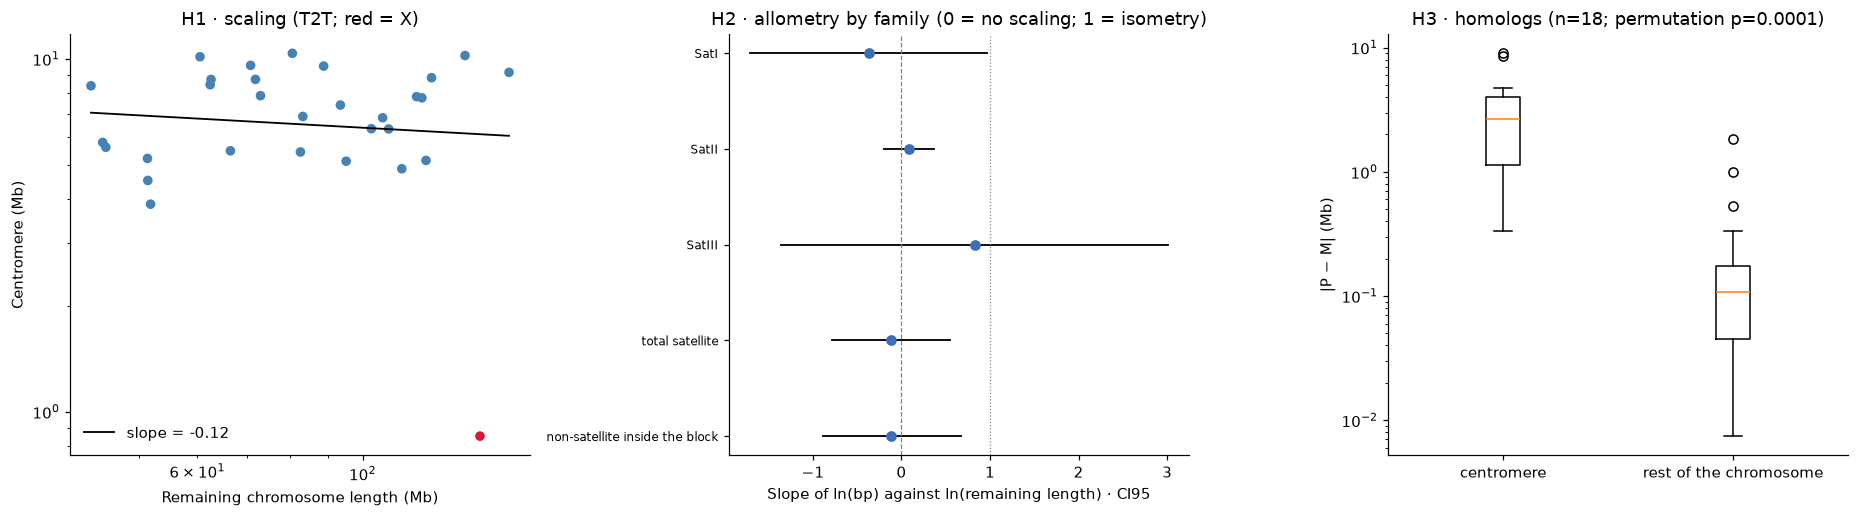

In [9]:
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
nums = lambda s: np.array(re.findall(r'-?\d+\.?\d*', s), float)

# (a) H1
a = ax[0]; a.scatter(D.rest_Mb, D.cen_Mb, c=np.where(D.kind == 'X', 'crimson', 'steelblue'), s=28)
xs = np.linspace(D.lrest.min(), D.lrest.max(), 50); pb = np.polyfit(D.lrest, D.lcen, 1)
a.plot(np.exp(xs), np.exp(np.polyval(pb, xs)), 'k-', lw=1.2, label=f'slope = {pb[0]:.2f}')
a.set_xscale('log'); a.set_yscale('log'); a.set_xlabel('Remaining chromosome length (Mb)'); a.set_ylabel('Centromere (Mb)')
a.set_title('H1 · scaling (T2T; red = X)'); a.legend(frameon=False)

# (b) H2: allometry by family (slope and CI95)
b = ax[1]; yy = np.arange(len(h2_fam))[::-1]
for y_, r in zip(yy, h2_fam.itertuples()):
    lo, hi = nums(r.CI95); b.plot([lo, hi], [y_, y_], 'k-', lw=1.2); b.plot(r.slope, y_, 'o', color='#3b6fb6')
b.axvline(0, color='gray', ls='--', lw=.8); b.axvline(1, color='gray', ls=':', lw=.8)
b.set_yticks(yy); b.set_yticklabels([m.split(' (')[0] for m in h2_fam.model], fontsize=8); b.set_xlabel('Slope of ln(bp) against ln(remaining length) · CI95')
b.set_title('H2 · allometry by family (0 = no scaling; 1 = isometry)')

# (c) H3 on the absolute scale
c = ax[2]; c.boxplot([H.dabs_cen_Mb.abs(), H.dabs_rest_Mb.abs()], showfliers=True); c.set_xticklabels(['centromere', 'rest of the chromosome']); c.set_yscale('log')
c.set_ylabel('|P − M| (Mb)'); c.set_title(f'H3 · homologs (n={len(H)}; permutation p={h3_sens.p_permutation.iloc[1]:.4f})')
plt.tight_layout(); plt.savefig(FIG/'summary.png', dpi=150); plt.show()

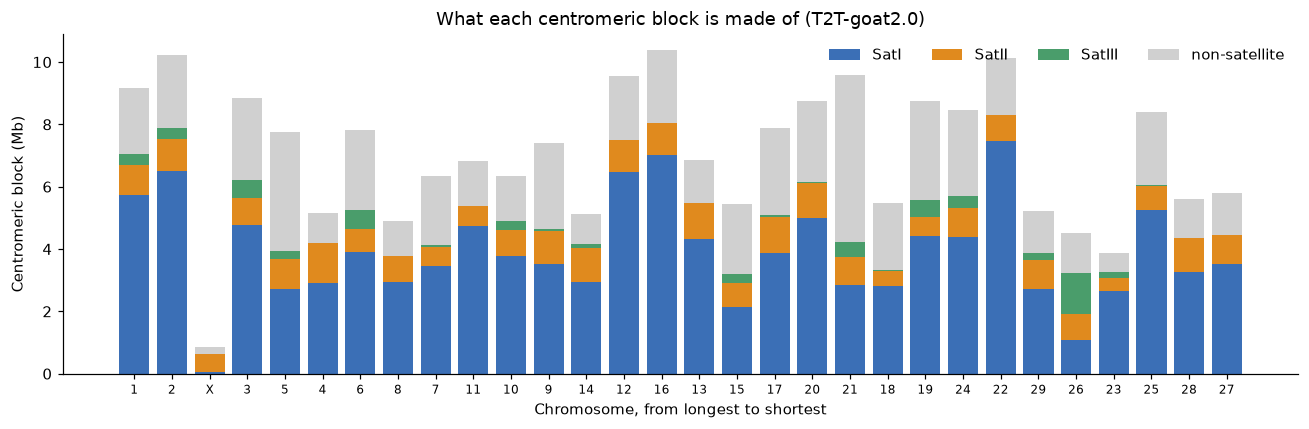

In [10]:
cols = {'SatI': '#3b6fb6', 'SatII': '#e08a1e', 'SatIII': '#4a9d6b'}
t = T[T.cen_len.notna()].sort_values('length', ascending=False)
fig, ax = plt.subplots(figsize=(12, 4)); x = np.arange(len(t)); bot = np.zeros(len(t))
for k in KINDS_SAT:
    v = t[k].to_numpy()/1e6; ax.bar(x, v, bottom=bot, color=cols[k], label=k, width=.8); bot += v
ax.bar(x, (t.cen_len.to_numpy() - t.sat_bp.to_numpy())/1e6, bottom=bot, color='#d0d0d0', label='non-satellite', width=.8)
ax.set_xticks(x); ax.set_xticklabels(t.chr.str.replace('CHI', ''), fontsize=8)
ax.set_xlabel('Chromosome, from longest to shortest'); ax.set_ylabel('Centromeric block (Mb)'); ax.legend(frameon=False, ncol=4)
ax.set_title('What each centromeric block is made of (T2T-goat2.0)')
plt.tight_layout(); plt.savefig(FIG/'composition_by_chromosome.png', dpi=150); plt.show()

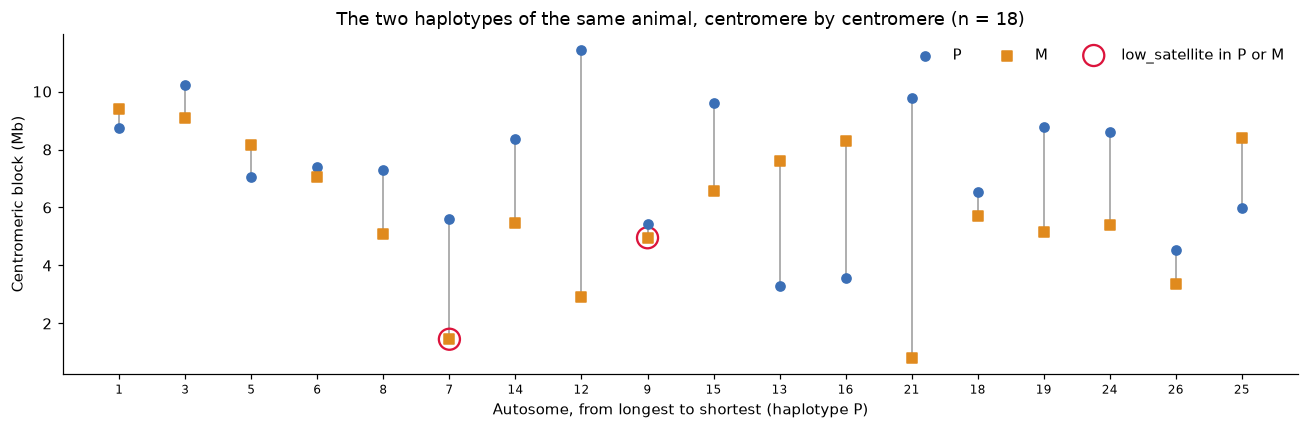

In [11]:
h = H.sort_values('length_P', ascending=False); x = np.arange(len(h))
fig, ax = plt.subplots(figsize=(12, 4))
ax.vlines(x, h.cen_len_P/1e6, h.cen_len_M/1e6, color='#999', lw=1)
ax.scatter(x, h.cen_len_P/1e6, color='#3b6fb6', s=36, label='P', zorder=3); ax.scatter(x, h.cen_len_M/1e6, color='#e08a1e', marker='s', s=36, label='M', zorder=3)
lo = h.low_sat.to_numpy()
ax.scatter(x[lo], (h.cen_len_M/1e6).to_numpy()[lo], facecolors='none', edgecolors='crimson', s=190, lw=1.5, label='low_satellite in P or M', zorder=2)
ax.set_xticks(x); ax.set_xticklabels(h.index.str.replace('CHI', ''), fontsize=8); ax.set_xlabel('Autosome, from longest to shortest (haplotype P)')
ax.set_ylabel('Centromeric block (Mb)'); ax.legend(frameon=False, ncol=3); ax.set_title(f'The two haplotypes of the same animal, centromere by centromere (n = {len(h)})')
plt.tight_layout(); plt.savefig(FIG/'haplotypes_by_chromosome.png', dpi=150); plt.show()

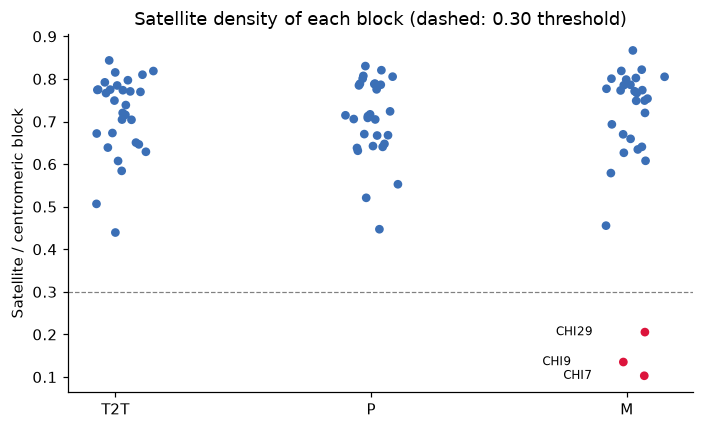

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4)); rng = np.random.default_rng(SEED)
for i, hp in enumerate(['T2T', 'P', 'M']):
    d = cen[(cen.hap == hp) & cen.sat_frac.notna()]
    xj = i + rng.normal(0, .06, len(d)); ax.scatter(xj, d.sat_frac, s=22, color=np.where(d.low_satellite, 'crimson', '#3b6fb6'))
    for xx, r in zip(xj, d.itertuples()):
        if r.low_satellite: ax.annotate('CHI' + r.chr.replace('CHI', ''), (xx, r.sat_frac), xytext=(-34, 0), textcoords='offset points', fontsize=8, va='center', ha='right')
ax.axhline(MIN_SAT_FRAC, color='gray', ls='--', lw=.8); ax.set_xticks(range(3)); ax.set_xticklabels(['T2T', 'P', 'M'])
ax.set_ylabel('Satellite / centromeric block'); ax.set_title('Satellite density of each block (dashed: 0.30 threshold)')
plt.tight_layout(); plt.savefig(FIG/'satellite_density_by_block.png', dpi=150); plt.show()

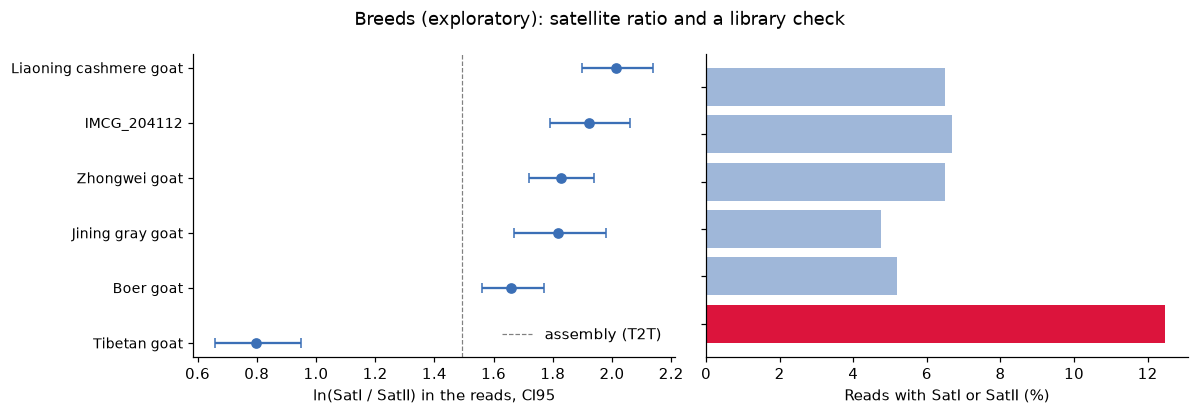

In [13]:
bp_ = TAB/'breeds_pacbio.csv'
if bp_.exists():
    br = pd.read_csv(bp_).sort_values('ln_SatI_SatII')
    ci = np.array([nums(s) for s in br.CI95_ln]); y = np.arange(len(br))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].errorbar(br.ln_SatI_SatII, y, xerr=[br.ln_SatI_SatII - ci[:, 0], ci[:, 1] - br.ln_SatI_SatII], fmt='o', color='#3b6fb6', capsize=3)
    ax[0].axvline(np.log(T.SatI.sum()/T.SatII.sum()), color='gray', ls='--', lw=.8, label='assembly (T2T)')
    ax[0].set_yticks(y); ax[0].set_yticklabels(br.individual, fontsize=9); ax[0].set_xlabel('ln(SatI / SatII) in the reads, CI95'); ax[0].legend(frameon=False, loc='lower right')
    ax[1].barh(y, br.frac_reads_with_satellite*100, color=np.where(br.individual.str.contains('Tibetan'), 'crimson', '#9fb7d9'))
    ax[1].set_yticks(y); ax[1].set_yticklabels([]); ax[1].set_xlabel('Reads with SatI or SatII (%)')
    plt.suptitle('Breeds (exploratory): satellite ratio and a library check'); plt.tight_layout(); plt.savefig(FIG/'breeds.png', dpi=150); plt.show()

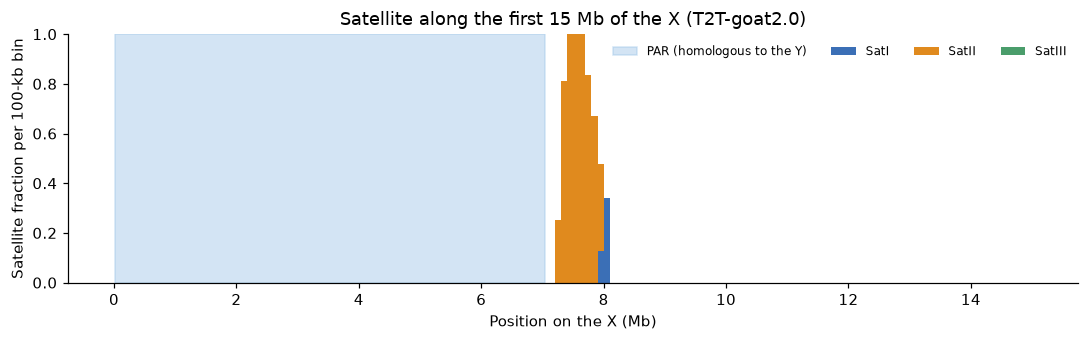

In [14]:
ax_ = pd.read_csv(TAB/'satellite_annotation.csv'); ax_ = ax_[(ax_.hap == 'T2T') & (ax_.chr == 'CHIX') & ax_.family.isin(KINDS_SAT)]
xc = pd.read_csv(TAB/'x_chromosome_check.csv').iloc[0]; nbin = 150; dens = {k: np.zeros(nbin) for k in KINDS_SAT}
for r in ax_.itertuples():
    for b in range(int(r.start // 1e5), min(nbin, int((r.end - 1) // 1e5) + 1)): dens[r.family][b] += min(r.end, (b + 1)*1e5) - max(r.start, b*1e5)
fig, ax = plt.subplots(figsize=(10, 3.2)); bot = np.zeros(nbin)
for k in KINDS_SAT: ax.bar(np.arange(nbin)/10 + .05, dens[k]/1e5, bottom=bot, width=.1, color=cols[k], label=k); bot += dens[k]/1e5
ax.axvspan(xc.PAR_X_start/1e6, xc.PAR_X_end/1e6, color='#9ec5e8', alpha=.45, label='PAR (homologous to the Y)')
ax.set_xlabel('Position on the X (Mb)'); ax.set_ylabel('Satellite fraction per 100-kb bin'); ax.legend(frameon=False, ncol=4, fontsize=8)
ax.set_title('Satellite along the first 15 Mb of the X (T2T-goat2.0)')
plt.tight_layout(); plt.savefig(FIG/'x_chromosome.png', dpi=150); plt.show()

## 3.6 · Results summary and export

In [15]:
summary = {
 'n_chromosomes_T2T': int(len(D)),
 'centromere_min_Mb': float(T.cen_len.min()/1e6), 'centromere_max_Mb': float(T.cen_len.max()/1e6), 'shortest_centromere_chromosome': T.loc[T.cen_len.idxmin(), 'chr'],
 'H1_slope': float(h1.slope.iloc[0]), 'H1_CI95': h1.CI95.iloc[0], 'H1_CI95_boot': h1.CI95_boot.iloc[0], 'H1_p_slope_0': float(h1.p_slope_0.iloc[0]),
 'H1_p_interaction_P_M': float(inter.p_interaction.iloc[0]),
 'H1_min_detectable_slope_without_X': float(h1_pot_res.min_detectable_slope_80.iloc[1]), 'H1_min_detectable_slope_with_X': float(h1_pot_res.min_detectable_slope_80.iloc[0]),
 'H2_delta_R2_ratio': float(h2.delta_R2.iloc[0]), 'H2_p_F': h2.p_F_txt.iloc[0], 'H2_delta_R2_without_X': float(h2.delta_R2.iloc[1]),
 'H3_n': int(h3.n_chromosomes.iloc[0]), 'H3_p_permutation_absolute': float(h3.p_permutation_absolute.iloc[0]),
 'H3_median_abs_diff_centromere_Mb': float(h3.median_abs_diff_centromere_Mb.iloc[0]), 'H3_median_abs_diff_rest_Mb': float(h3.median_abs_diff_rest_Mb.iloc[0]),
 'n_low_satellite_blocks': int(cen.low_satellite.sum()),
 'H3_n_without_low_satellite': int(h3_sens.set_index('comparison').loc['absolute (Mb) — without low-satellite blocks', 'n']),
 'H3_p_permutation_without_low_satellite': float(h3_sens.set_index('comparison').loc['absolute (Mb) — without low-satellite blocks', 'p_permutation']),
}
(TAB/'results_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "n_chromosomes_T2T": 30,
  "centromere_min_Mb": 0.8528,
  "centromere_max_Mb": 10.3755,
  "shortest_centromere_chromosome": "CHIX",
  "H1_slope": -0.11661433282533343,
  "H1_CI95": "[-0.80, 0.57]",
  "H1_CI95_boot": "[-0.81, 0.38]",
  "H1_p_slope_0": 0.7384080953687185,
  "H1_p_interaction_P_M": 0.6432414100880357,
  "H1_min_detectable_slope_without_X": 0.394399348905976,
  "H1_min_detectable_slope_with_X": 0.6622373892238271,
  "H2_delta_R2_ratio": 0.7327483620539236,
  "H2_p_F": "< 1e-4",
  "H2_delta_R2_without_X": 0.2534105610718247,
  "H3_n": 18,
  "H3_p_permutation_absolute": 5.340576171875e-05,
  "H3_median_abs_diff_centromere_Mb": 2.6712,
  "H3_median_abs_diff_rest_Mb": 0.106861,
  "n_low_satellite_blocks": 3,
  "H3_n_without_low_satellite": 16,
  "H3_p_permutation_without_low_satellite": 1.52587890625e-05
}


### Files written to `data/`
| File | Content |
|---|---|
| `chromosomes.csv`, `manifest.csv`, `public_runs.csv` | chromosome lengths by haplotype, download traceability and the PacBio catalogue |
| `srf_units.csv`, `satellites_SatI-III.fa`, `srf.fa` | satellite units and their classification |
| `satellite_annotation.csv` | SatI–III intervals by chromosome and haplotype |
| `centromeres.csv`, `centromeres_master.csv` | centromeres by chromosome and haplotype (the master table adds derived columns) |
| `qc_*.csv`, `proximal_gaps.csv` | quality controls: orientation, windows, gaps |
| `x_chromosome_check.csv` | evidence on the position of the X centromere |
| `H1_scaling.csv`, `H1_influence.csv`, `H1_interaction.csv`, `H1_power*.csv` | scaling, influence, P against M interaction, power |
| `H2_family_allometry.csv`, `H2_composition.csv`, `H2_influence.csv`, `H1H2_chromosome_table_T2T.csv` | satellite composition |
| `H3_homologs.csv`, `H3_summary.csv`, `H3_sensitivity.csv` | homologs, P against M |
| `breeds_pacbio.csv` | variation between breeds (exploratory) |
| `figures/*.png`, `results_summary.json` | figures and summary |